In [1]:
import os
import sys

# Get the absolute path of the directory containing the notebook (notebooks/)
current_dir = os.path.abspath('')

# Add the parent directory (SingleWordProductionDutch/) to the system path
# This allows Python to find 'src'
parent_dir = os.path.dirname(current_dir)
sys.path.append(parent_dir)

import numpy as np
import scipy.signal
from scipy.signal import hilbert
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import pearsonr
from pynwb import NWBHDF5IO
from sklearn.metrics import mean_squared_error

import pandas as pd
import numpy.matlib as matlib
import scipy.signal
from notebookfunctions import *

feat_path = r'./features'
result_path = r'./results'


winL = 0.05
frameshift = 0.01
modelOrder = 4
stepSize = 5
sr=1024
path_bids = '/Users/lisa/Documents/DSAI_year2/Marble/SingleWordProductionDutch/SingleWordProductionDutch-iBIDS'
path_somata = '/Users/lisa/Documents/DSAI_year2/SingleWordProductionDutch-1/somata'

In [7]:

duration_sec = 6
t_start = 2
feat_sr = 1 / 0.01  # if frameshift is 0.01s

# 2. Calculate indices based on the FEATURE clock
start_win = int(t_start * feat_sr)
# 2 seconds of data = 200 windows
num_wins = int(duration_sec * feat_sr) 
end_win = start_win + num_wins

# 3. Create a time vector that matches the length of the features (200,)
t = np.linspace(t_start, t_start + duration_sec, num_wins)

def get_feat_for_plt(pt, ch_idx):
    hga = np.load(os.path.join(feat_path,f'{pt}_unstacked_feat.npy'))
    sspe = np.load(os.path.join(feat_path,f'{pt}_unstacked_SSPEfeat.npy'))

    #print(f'hga.shape: {hga.shape}, sspe.shape: {sspe.shape}')
    
    
    feat_hga = hga[start_win : end_win, ch_idx].flatten()
    feat_hga_norm = (feat_hga - np.mean(feat_hga)) / np.std(feat_hga) # Normalize for visual comparison (z-score) so they sit on top of each other
    
    initParams_list = get_initParams(pt)
    initParams = initParams_list[ch_idx]

    start_col = 0
    for i in range(ch_idx):
        start_col += len(initParams_list[i]['freqs'])
    
    # The number of oscillators for the current channel
    current_n_osc = len(initParams_list[ch_idx]['freqs'])

    # Get the individual oscillator columns for this channel
    individual_oscs = sspe[start_win : end_win, start_col : start_col + current_n_osc]
    
    # Sum them for the total SSPE feature
    feat_sspe = np.sum(individual_oscs, axis=1)
    
    if np.std(feat_sspe) ==0:
        print(f"std sspe: {np.std(feat_sspe)}, ch_idx: {ch_idx}")
        print('feat sspe ',feat_sspe)
        feat_sspe_norm = feat_sspe
    feat_sspe_norm = (feat_sspe - np.mean(feat_sspe)) / np.std(feat_sspe)

    
    # Normalize individual oscillators for comparison
    # return these as a list of normalized arrays
    indiv_oscs_norm = []
    for i in range(current_n_osc):
        osc = individual_oscs[:, i]
        if np.std(osc) > 0:
            indiv_oscs_norm.append((osc - np.mean(osc)) / np.std(osc))
        else:
            indiv_oscs_norm.append(osc) # handle zero-variance case
    
    #raw data features
    winL = 0.05
    frameshift = 0.01
    modelOrder = 4
    stepSize = 5
    path_bids = '/Users/lisa/Documents/DSAI_year2/Marble/SingleWordProductionDutch/SingleWordProductionDutch-iBIDS'
    io = NWBHDF5IO(os.path.join(path_bids,pt,'ieeg',f'{pt}_task-wordProduction_ieeg.nwb'), 'r')
    nwbfile = io.read()
    data = nwbfile.acquisition['iEEG'].data[:]
    io.close()
    
    #Small helper function to speed up the hilbert transform by extending the length of data to the next power of 2
    hilbert3 = lambda x: scipy.signal.hilbert(x, scipy.fftpack.next_fast_len(len(x)),axis=0)[:len(x)]
    
    numWindows = int(np.floor((data.shape[0]-winL*sr)/(frameshift*sr)))
 
    #Create feature space
    data = np.abs(hilbert3(data))
    feat = np.zeros((numWindows,data.shape[1]))
    for win in range(numWindows):
        start= int(np.floor((win*frameshift)*sr))
        stop = int(np.floor(start+winL*sr))
        feat[win,:] = np.mean(data[start:stop,:],axis=0)
    
    raw_envelope = feat[start_win : end_win, ch_idx]
    
    # Normalize for visual comparison so they sit on top of each other
    raw_envelope_norm = (raw_envelope - np.mean(raw_envelope)) / np.std(raw_envelope)

    #get the center frequencies for labeling individual plots
    freqs = somata_results[ch_idx]['freqs']
    
    return raw_envelope_norm, feat_hga_norm, feat_sspe_norm, indiv_oscs_norm, freqs

nr of frequencies in somata results in total: 481
channel 1 for participant sub-07:
fit hga to raw envelope
Correlation (r): 0.0652
RMSE:            1.3673
R-squared:       -0.8696

fit sspe to raw envelope
Correlation (r): 0.4847
RMSE:            1.0152
R-squared:       -0.0306

SSPE vs HGA features correlation: 0.0873


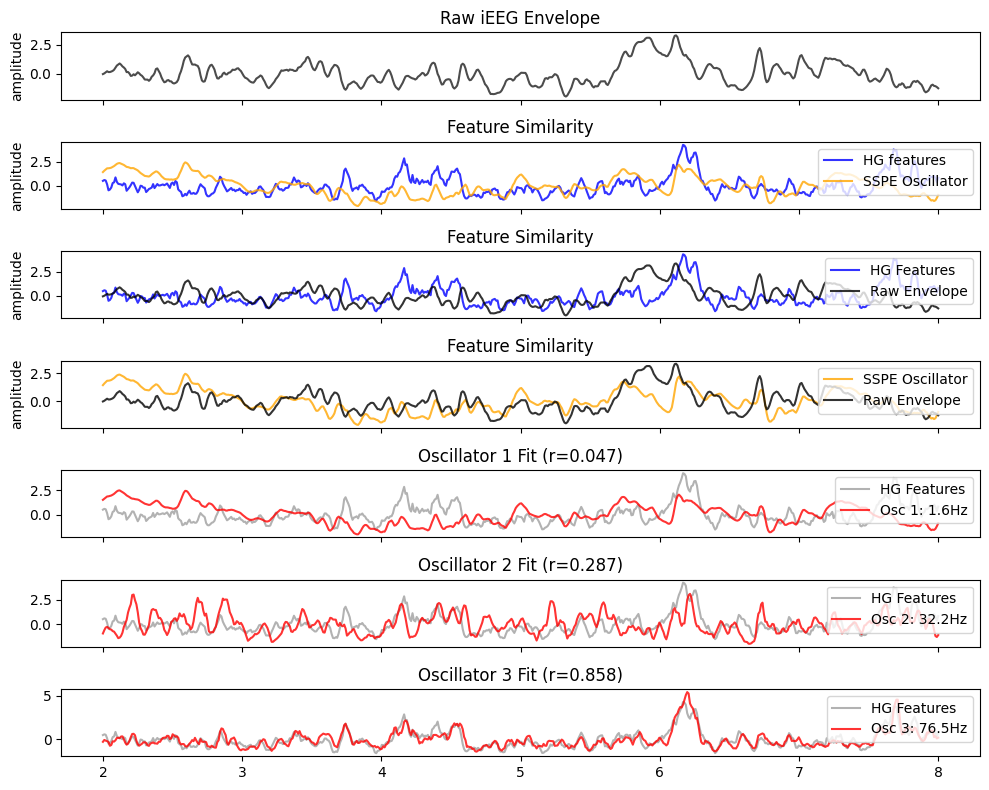

nr of frequencies in somata results in total: 481
channel 2 for participant sub-07:
fit hga to raw envelope
Correlation (r): 0.0733
RMSE:            1.3614
R-squared:       -0.8535

fit sspe to raw envelope
Correlation (r): 0.7266
RMSE:            0.7394
R-squared:       0.4533

SSPE vs HGA features correlation: 0.1163


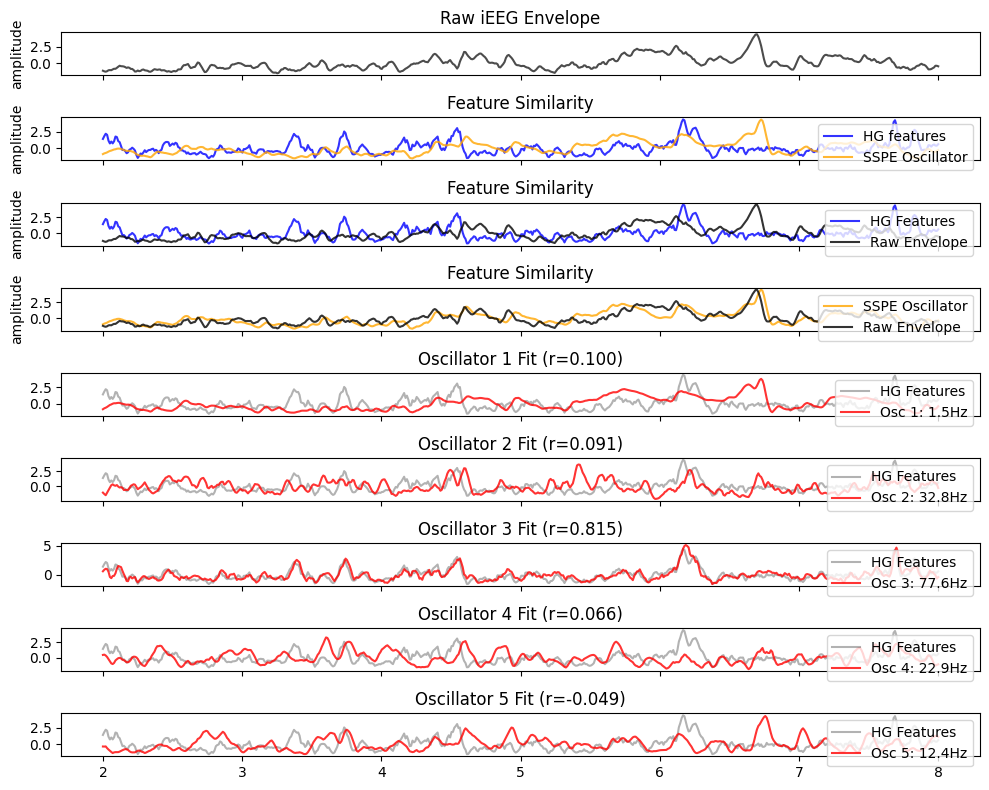

nr of frequencies in somata results in total: 481
channel 3 for participant sub-07:
fit hga to raw envelope
Correlation (r): -0.0201
RMSE:            1.4284
R-squared:       -1.0402

fit sspe to raw envelope
Correlation (r): 0.8541
RMSE:            0.5402
R-squared:       0.7082

SSPE vs HGA features correlation: -0.0311


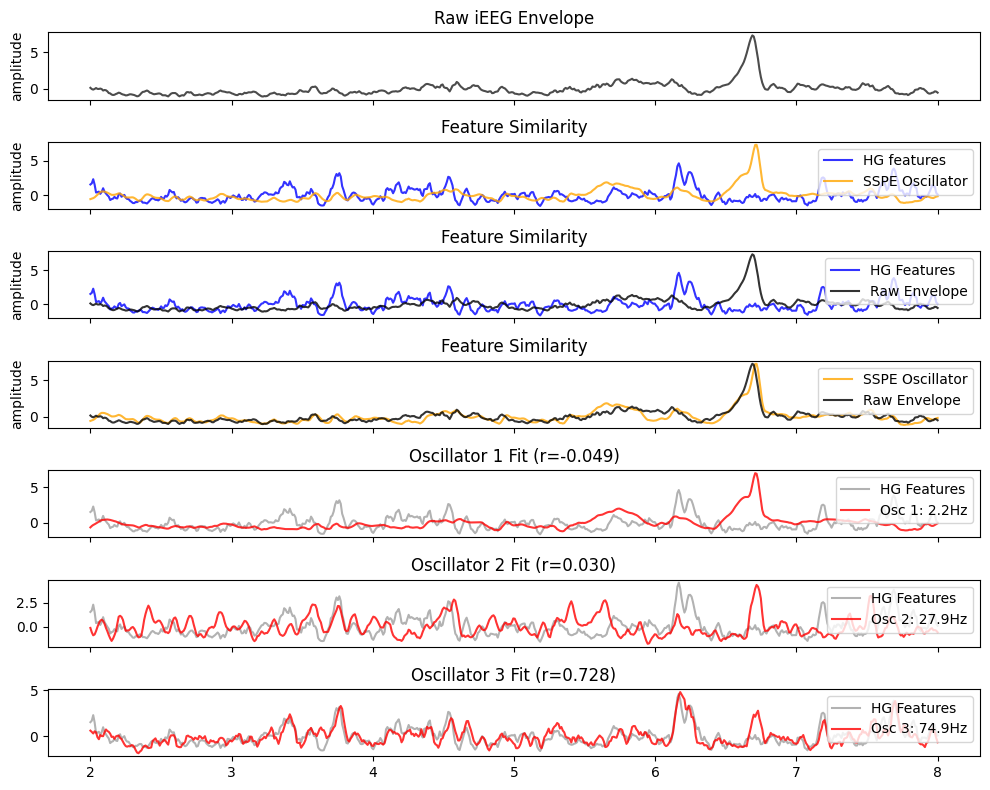

nr of frequencies in somata results in total: 481
channel 4 for participant sub-07:
fit hga to raw envelope
Correlation (r): -0.0520
RMSE:            1.4505
R-squared:       -1.1040

fit sspe to raw envelope
Correlation (r): 0.7030
RMSE:            0.7707
R-squared:       0.4061

SSPE vs HGA features correlation: -0.0193


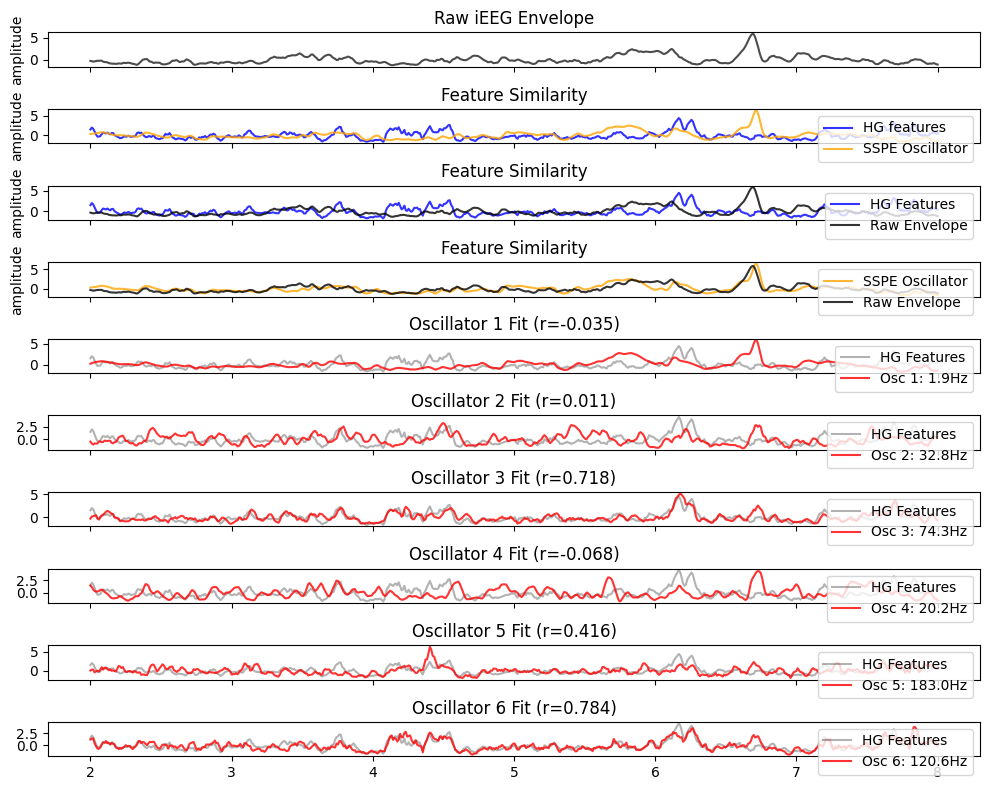

In [8]:


pt = 'sub-07'

#ch = [50, 8, 51, 101, 52]
ch = [96, 95, 94, 97, 1] #


for ch_idx in range(1,5):
    raw_envelope_norm, feat_hga_norm, feat_sspe_norm, indiv_oscs_norm, freqs = get_feat_for_plt(pt, ch_idx)
    print(f'channel {ch_idx} for participant {pt}:')
    
    # Correlation measures the linear relationship (timing/envelope similarity)
    corr, _ = pearsonr(feat_hga_norm, raw_envelope_norm)
    # RMSE measures the absolute difference (fit quality)
    rmse = np.sqrt(mean_squared_error(feat_hga_norm, raw_envelope_norm))
    #R-squared
    ss_res = np.sum((raw_envelope_norm - feat_hga_norm) ** 2)
    ss_tot = np.sum((raw_envelope_norm - np.mean(raw_envelope_norm)) ** 2)
    r_sq = 1 - (ss_res / ss_tot)

    print("fit hga to raw envelope")
    print(f'Correlation (r): {corr:.4f}')
    print(f'RMSE:            {rmse:.4f}')
    print(f'R-squared:       {r_sq:.4f}\n')
    
    # now for hga vs raw
    corr, _ = pearsonr(raw_envelope_norm, feat_sspe_norm)
    # RMSE measures the absolute difference (fit quality)
    rmse = np.sqrt(mean_squared_error(raw_envelope_norm, feat_sspe_norm))
    #R-squared
    ss_res = np.sum((raw_envelope_norm - feat_sspe_norm) ** 2)
    ss_tot = np.sum((raw_envelope_norm - np.mean(raw_envelope_norm)) ** 2)
    r_sq = 1 - (ss_res / ss_tot)

    print("fit sspe to raw envelope")
    print(f'Correlation (r): {corr:.4f}')
    print(f'RMSE:            {rmse:.4f}')
    print(f'R-squared:       {r_sq:.4f}\n')

    # Correlation between standard Hilbert HGA and your SSPE version
    r_val, _ = pearsonr(feat_hga_norm, feat_sspe_norm)
    print(f"SSPE vs HGA features correlation: {r_val:.4f}")
    
    
    fig, axes = plt.subplots(4 + len(indiv_oscs_norm), 1, figsize=(10, 8), sharex=True)
    
    # Top: Raw iEEG Feature (Broadband baseline)
    axes[0].plot(t, raw_envelope_norm, color='black', alpha=0.7)
    axes[0].set_title(f'Raw iEEG Envelope')
    axes[0].set_ylabel('amplitude')
    
    # Middle: HGA vs SSPE Similarity
    axes[1].plot(t, feat_hga_norm, label='HG features', color='blue', alpha=0.8)
    axes[1].plot(t, feat_sspe_norm, label='SSPE Oscillator', color='orange', alpha=0.8)
    axes[1].set_title(f'Feature Similarity')
    axes[1].set_ylabel('amplitude')
    axes[1].legend(loc='upper right')

    # HGA vs raw Similarity
    axes[2].plot(t, feat_hga_norm, label='HG Features', color='blue', alpha=0.8)
    axes[2].plot(t, raw_envelope_norm, label='Raw Envelope', color='black', alpha=0.8)
    axes[2].set_title(f'Feature Similarity')
    axes[2].set_ylabel('amplitude')
    axes[2].legend(loc='upper right')

    # raw vs SSPE Similarity
    axes[3].plot(t, feat_sspe_norm, label='SSPE Oscillator', color='orange', alpha=0.8)
    axes[3].plot(t, raw_envelope_norm, label='Raw Envelope', color='black', alpha=0.8)
    axes[3].set_title(f'Feature Similarity')
    axes[3].set_ylabel('amplitude')
    axes[3].legend(loc='upper right')

    # plot individual oscillators
    for i, osc_data in enumerate(indiv_oscs_norm):
        ax_idx = 4 + i
        axes[ax_idx].plot(t, feat_hga_norm, color='black', alpha=0.3, label='HG Features')
        axes[ax_idx].plot(t, osc_data, color='red', alpha=0.8, label=f'Osc {i+1}: {freqs[i]:.1f}Hz')
        
        # Calculate correlation for this specific frequency
        r, _ = pearsonr(feat_hga_norm, osc_data)
        axes[ax_idx].set_title(f'Oscillator {i+1} Fit (r={r:.3f})')
        axes[ax_idx].legend(loc='upper right')
    
    plt.tight_layout()
    plt.show()

nr of frequencies in somata results in total: 174
Correlations for sub-08 Channel 1
Osc 1 (0.0 Hz): r = 0.350
Osc 2 (187.2 Hz): r = 0.136
Osc 3 (255.0 Hz): r = 0.173
Osc 4 (116.1 Hz): r = 0.178


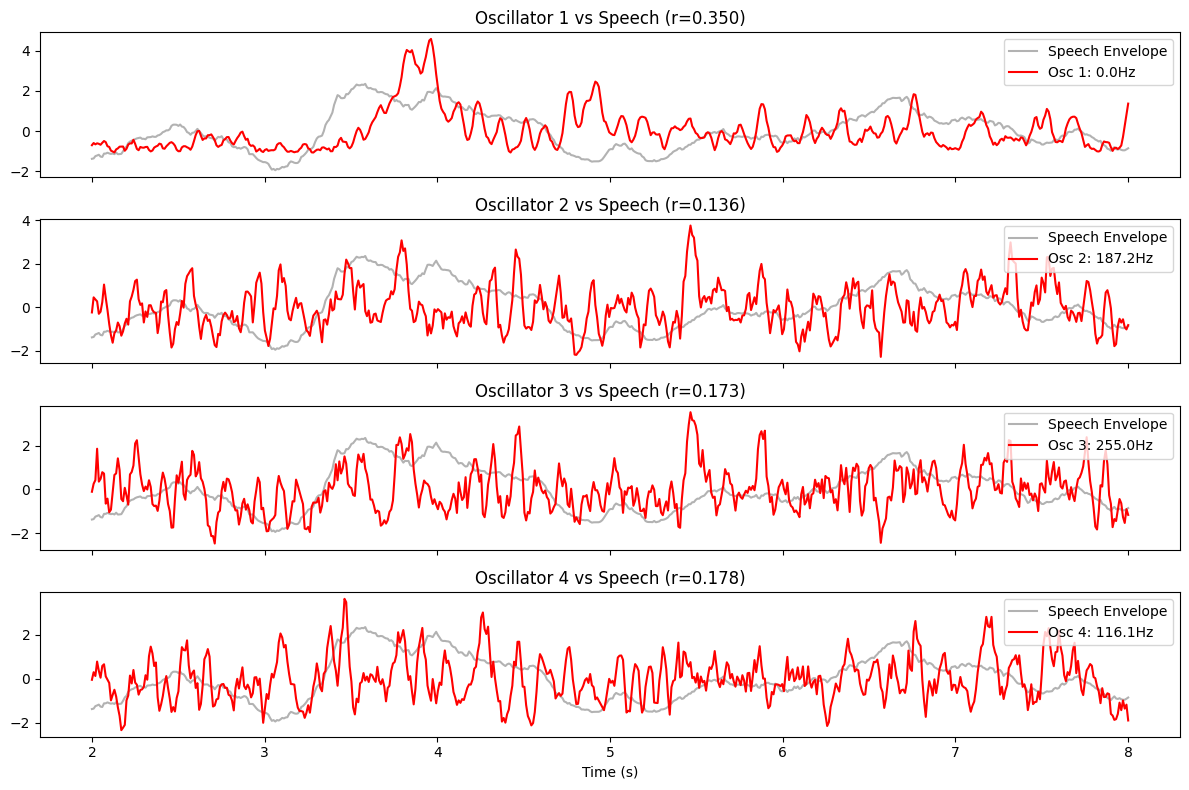

Correlations for sub-08 Channel 2
Osc 1 (0.0 Hz): r = -0.226
Osc 2 (202.2 Hz): r = 0.068
Osc 3 (125.8 Hz): r = 0.115


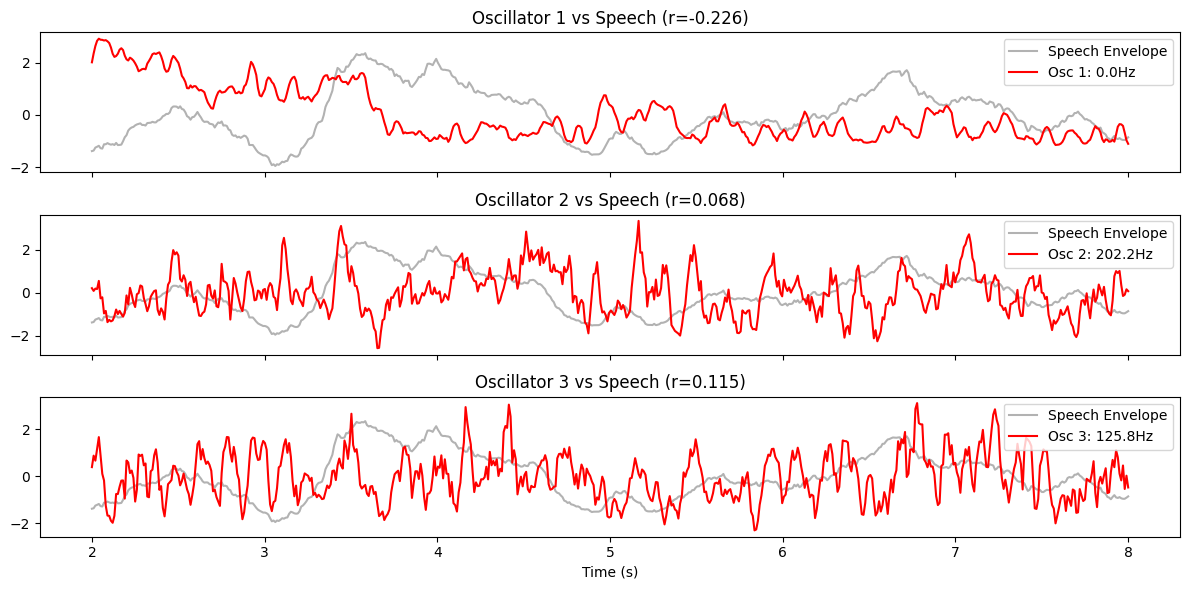

Correlations for sub-08 Channel 3
Osc 1 (3.9 Hz): r = 0.166
Osc 2 (35.7 Hz): r = 0.283
Osc 3 (37.3 Hz): r = 0.225
Osc 4 (104.2 Hz): r = 0.315


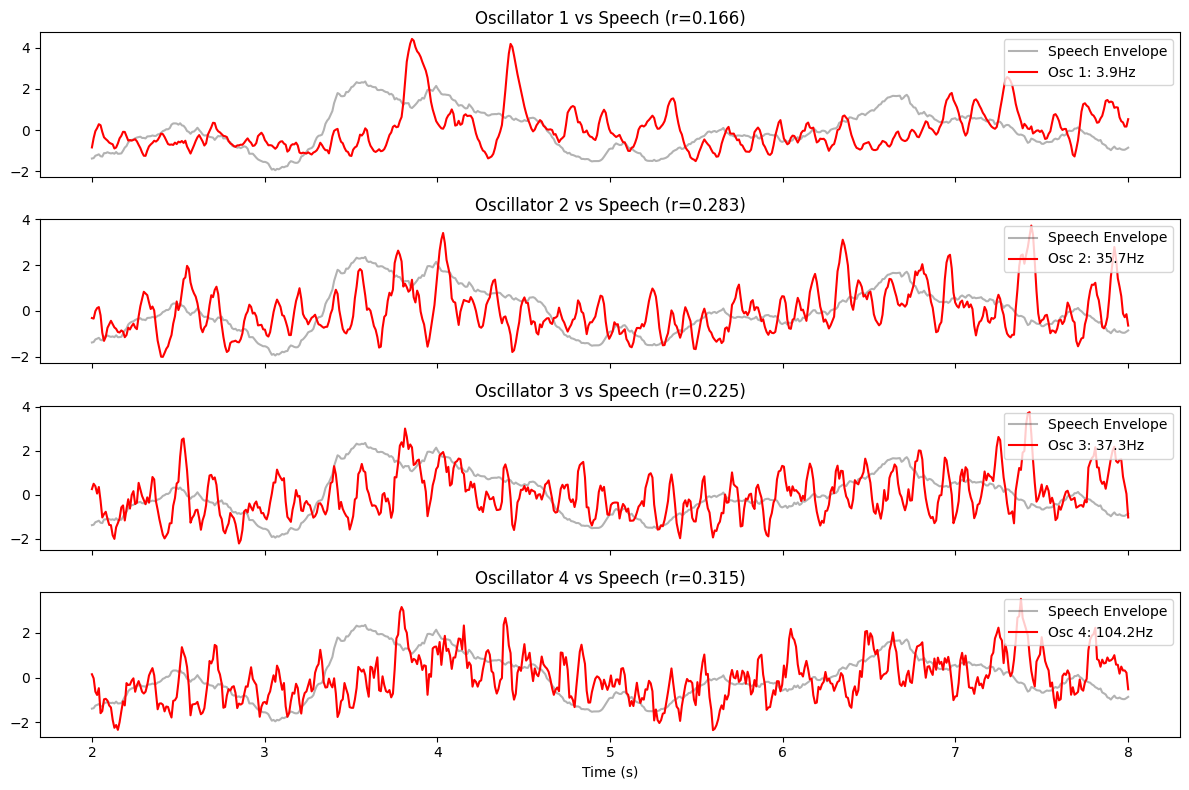

Correlations for sub-08 Channel 4
Osc 1 (5.4 Hz): r = 0.018
Osc 2 (24.8 Hz): r = 0.057
Osc 3 (117.6 Hz): r = 0.202
Osc 4 (112.1 Hz): r = 0.231


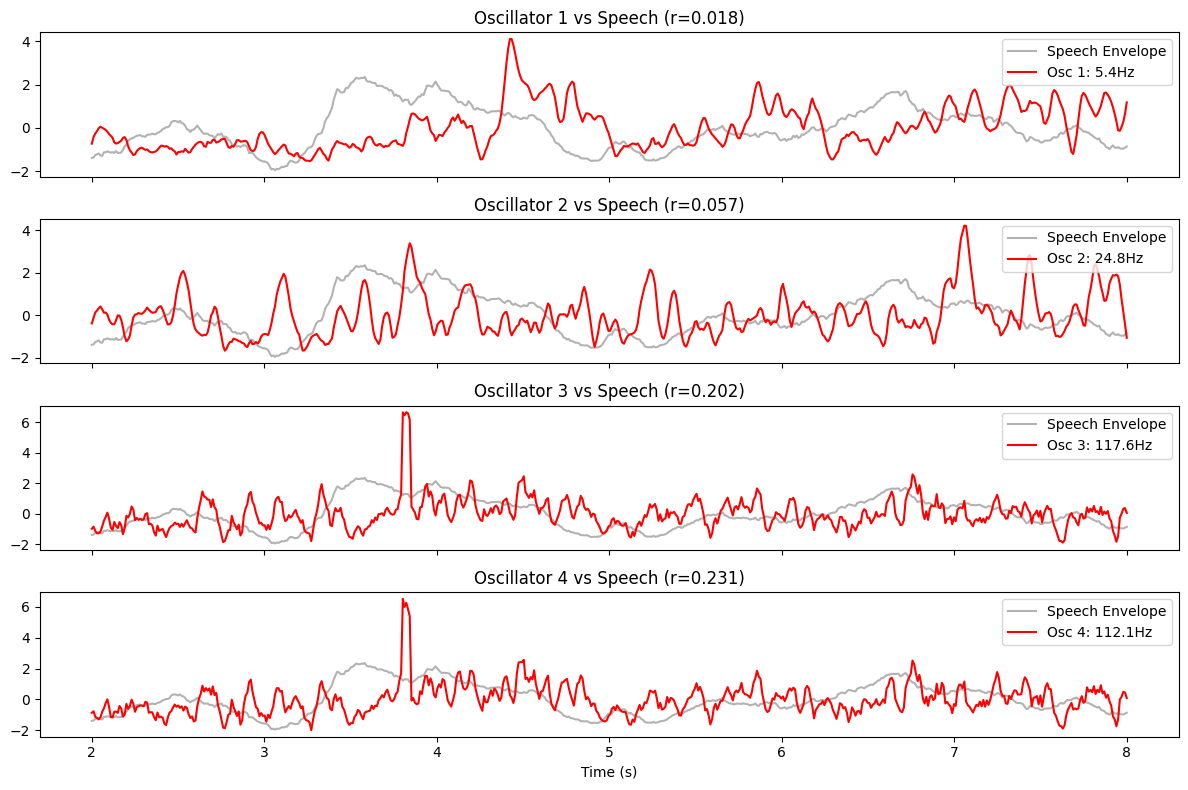

Correlations for sub-08 Channel 5
Osc 1 (7.4 Hz): r = 0.136
Osc 2 (19.2 Hz): r = 0.119
Osc 3 (0.8 Hz): r = -0.140
Osc 4 (71.7 Hz): r = 0.342


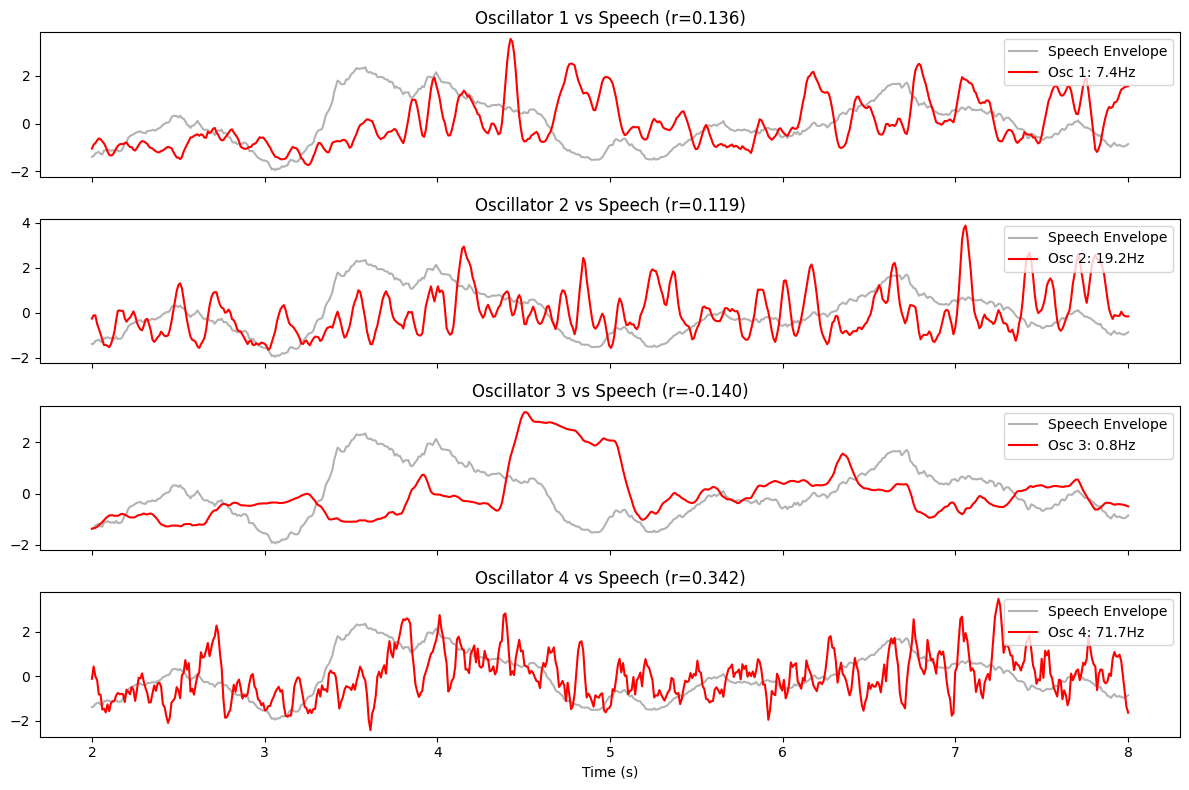

In [16]:
#correlation of individual oscs to the predicted spectogram
pt = 'sub-08'
sspe = np.load(os.path.join(feat_path,f'{pt}_unstacked_SSPEfeat.npy'))
initParams_list = get_initParams(pt)

for ch_idx in [1, 2, 3, 4, 5]:

    initParams = initParams_list[ch_idx]
    start_col = 0
    for i in range(ch_idx):
        start_col += len(initParams_list[i]['freqs'])
    freqs = initParams_list[ch_idx]['freqs']
    current_n_osc = len(freqs)
    individual_oscs = sspe[start_win : end_win, start_col : start_col + current_n_osc]
    
    
    #Get Audio Envelope (Mean of all 23 spec bins) # This represents the overall loudness/energy of the speech
    rec_spec = np.load(os.path.join(result_path,f'{pt}_predicted_spec.npy'))
    audio_env = np.mean(rec_spec[start_win:end_win, :], axis=1)
    audio_env_norm = (audio_env - np.mean(audio_env)) / np.std(audio_env)
    
    #Plot:
    fig, axes = plt.subplots(current_n_osc, 1, figsize=(12, 2 * current_n_osc), sharex=True)
    
    print(f"Correlations for {pt} Channel {ch_idx}")
    
    for i in range(current_n_osc):
        osc_data = individual_oscs[:, i]
        osc_norm = (osc_data - np.mean(osc_data)) / np.std(osc_data)
        
        # Calculate Correlation
        r, _ = pearsonr(osc_norm, audio_env_norm)
        print(f"Osc {i+1} ({freqs[i]:.1f} Hz): r = {r:.3f}")
    
        axes[i].plot(t, audio_env_norm, color='black', alpha=0.3, label='Speech Envelope')
        axes[i].plot(t, osc_norm, color='red', label=f'Osc {i+1}: {freqs[i]:.1f}Hz')
        axes[i].set_title(f'Oscillator {i+1} vs Speech (r={r:.3f})')
        axes[i].legend(loc='upper right')
    
    plt.xlabel('Time (s)')
    plt.tight_layout()
    plt.show()

nr of frequencies in somata results in total: 481
Correlations for sub-07 Channel 1
Osc 1 (1.6 Hz): r = -0.110
Osc 2 (32.2 Hz): r = 0.169
Osc 3 (76.5 Hz): r = 0.055


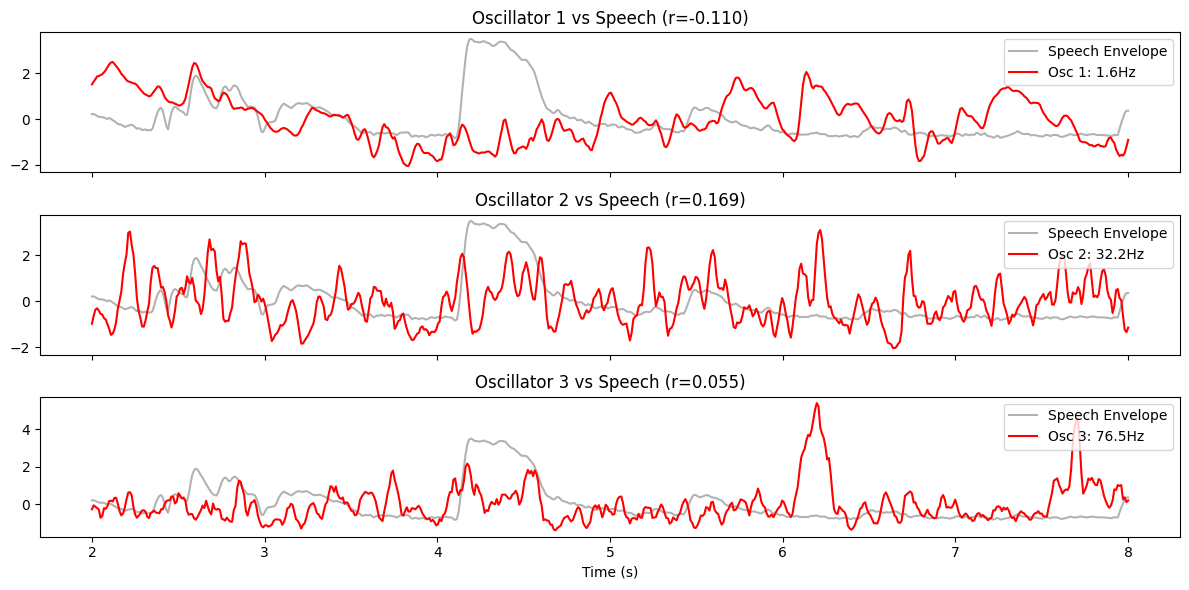

Correlations for sub-07 Channel 2
Osc 1 (1.5 Hz): r = -0.108
Osc 2 (32.8 Hz): r = 0.087
Osc 3 (77.6 Hz): r = 0.030
Osc 4 (22.9 Hz): r = -0.194
Osc 5 (12.4 Hz): r = -0.039


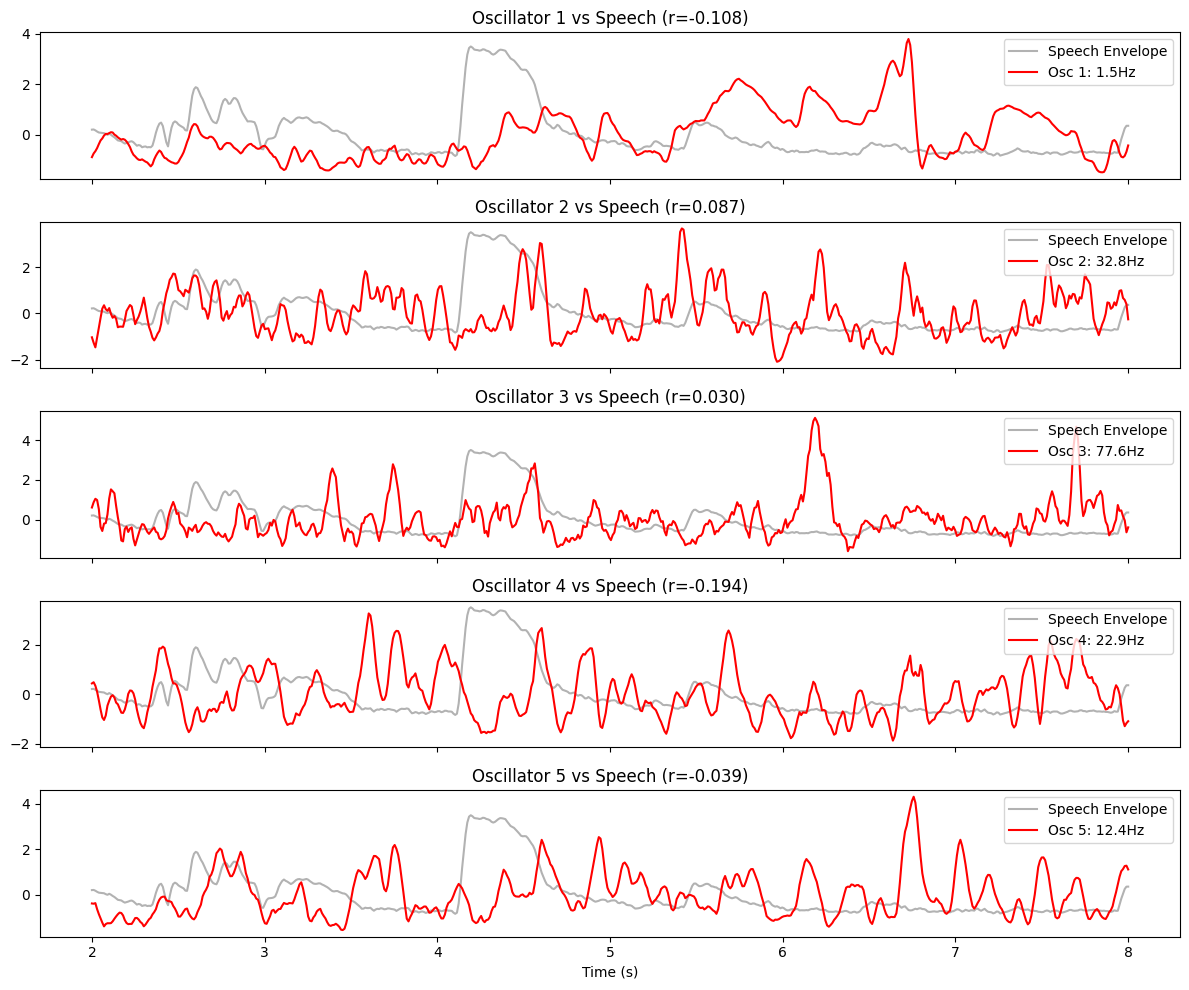

Correlations for sub-07 Channel 3
Osc 1 (2.2 Hz): r = -0.146
Osc 2 (27.9 Hz): r = -0.005
Osc 3 (74.9 Hz): r = -0.020


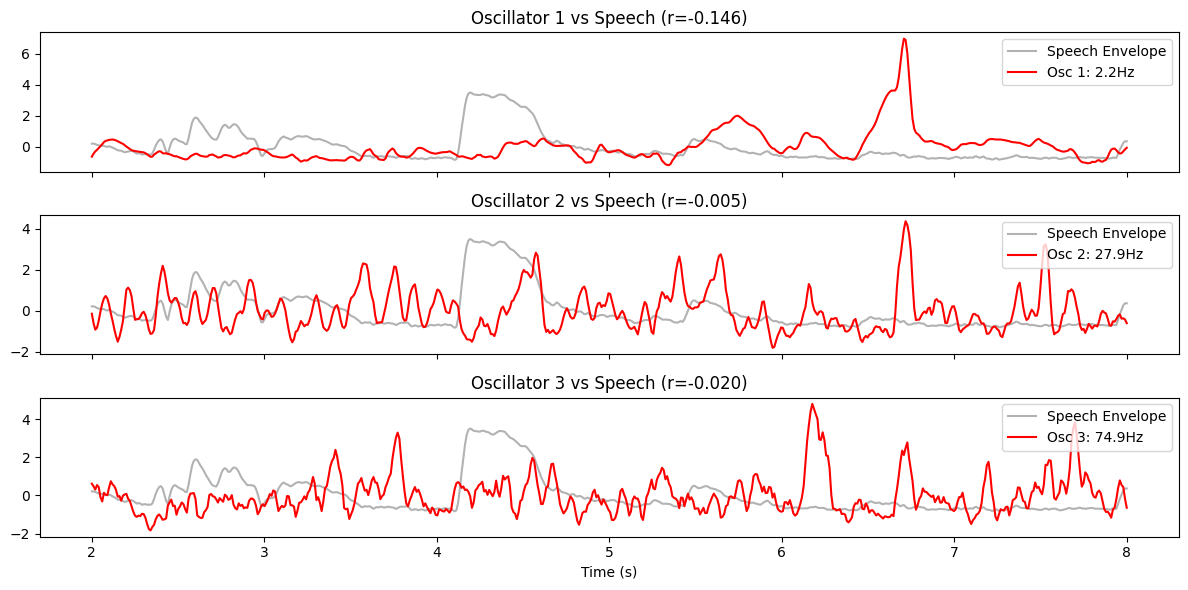

Correlations for sub-07 Channel 4
Osc 1 (1.9 Hz): r = -0.272
Osc 2 (32.8 Hz): r = 0.119
Osc 3 (74.3 Hz): r = 0.093
Osc 4 (20.2 Hz): r = -0.224
Osc 5 (183.0 Hz): r = 0.307
Osc 6 (120.6 Hz): r = 0.213


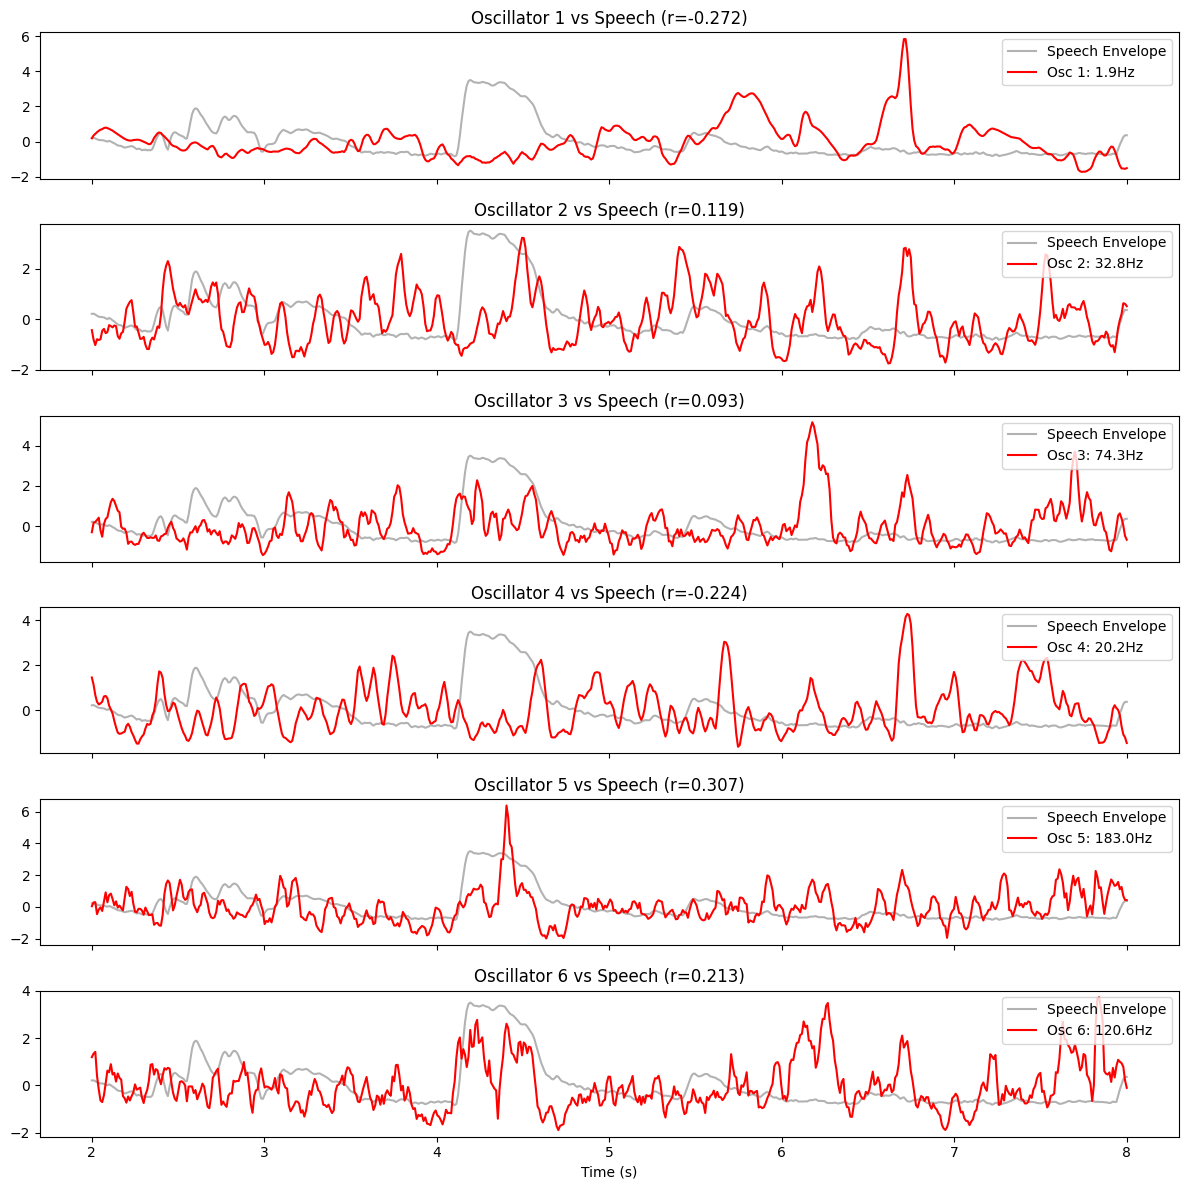

Correlations for sub-07 Channel 5
Osc 1 (1.8 Hz): r = -0.296
Osc 2 (0.1 Hz): r = 0.020
Osc 3 (85.5 Hz): r = 0.098


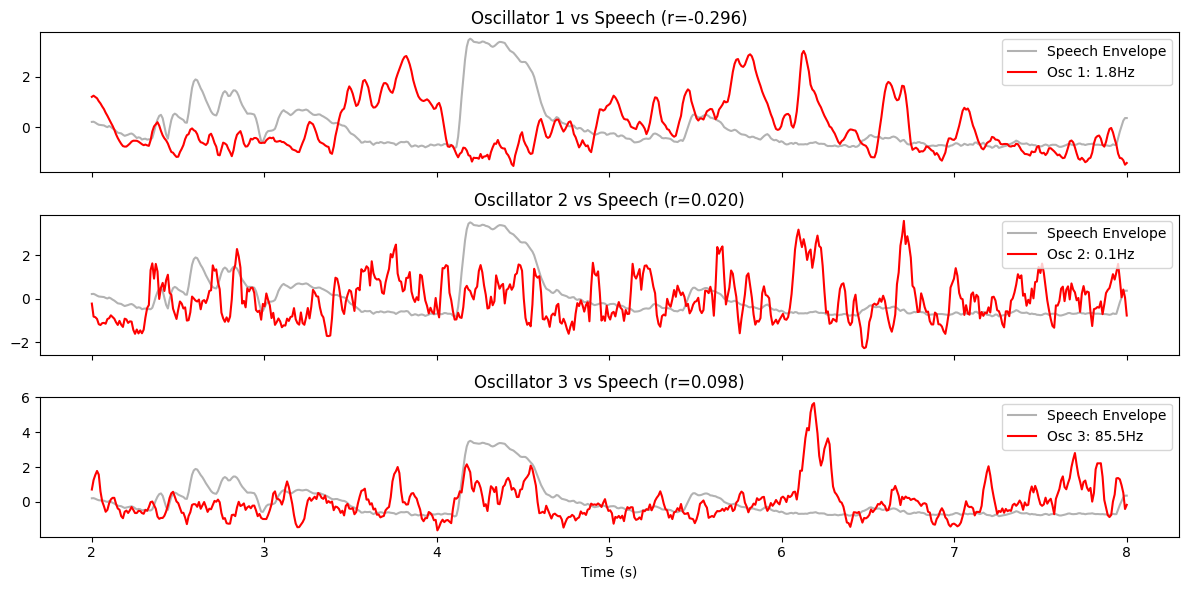

In [18]:
#correlation of individual oscs to the actual spectogram
pt = 'sub-07'
sspe = np.load(os.path.join(feat_path,f'{pt}_unstacked_SSPEfeat.npy'))
initParams_list = get_initParams(pt)

for ch_idx in [1, 2, 3, 4, 5]:

    initParams = initParams_list[ch_idx]
    start_col = 0
    for i in range(ch_idx):
        start_col += len(initParams_list[i]['freqs'])
    freqs = initParams_list[ch_idx]['freqs']
    current_n_osc = len(freqs)
    individual_oscs = sspe[start_win : end_win, start_col : start_col + current_n_osc]
    
    
    #Get Audio Envelope (Mean of all 23 spec bins) # This represents the overall loudness/energy of the speech
    spec = np.load(os.path.join(feat_path,f'{pt}_spec.npy'))
    audio_env = np.mean(spec[start_win:end_win, :], axis=1)
    audio_env_norm = (audio_env - np.mean(audio_env)) / np.std(audio_env)
    
    #Plot:
    fig, axes = plt.subplots(current_n_osc, 1, figsize=(12, 2 * current_n_osc), sharex=True)
    
    print(f"Correlations for {pt} Channel {ch_idx}")
    
    for i in range(current_n_osc):
        osc_data = individual_oscs[:, i]
        osc_norm = (osc_data - np.mean(osc_data)) / np.std(osc_data)
        
        # Calculate Correlation
        r, _ = pearsonr(osc_norm, audio_env_norm)
        print(f"Osc {i+1} ({freqs[i]:.1f} Hz): r = {r:.3f}")
    
        axes[i].plot(t, audio_env_norm, color='black', alpha=0.3, label='Speech Envelope')
        axes[i].plot(t, osc_norm, color='red', label=f'Osc {i+1}: {freqs[i]:.1f}Hz')
        axes[i].set_title(f'Oscillator {i+1} vs Speech (r={r:.3f})')
        axes[i].legend(loc='upper right')
    
    plt.xlabel('Time (s)')
    plt.tight_layout()
    plt.show()

nr of frequencies in somata results in total: 481
total nr of freqs: 503


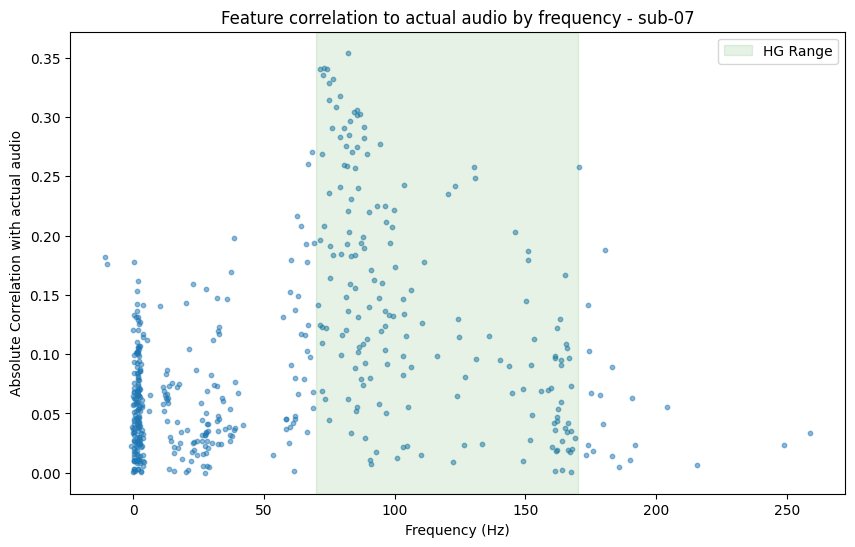

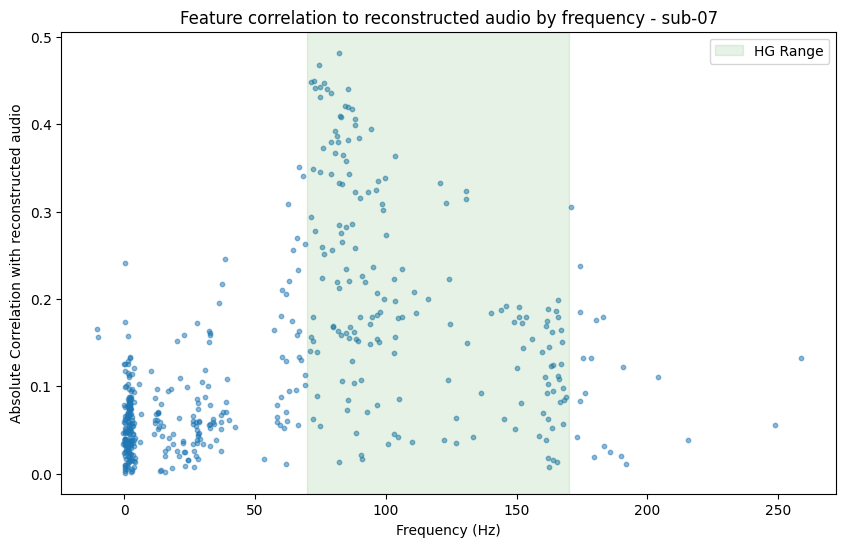

In [36]:

for pt in pts:
    sspe = np.load(os.path.join(feat_path,f'{pt}_unstacked_SSPEfeat.npy'))
    initParams_list = get_initParams(pt)
    
    spectrogram = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
    audio_env = np.mean(spectrogram, axis=1)
    audio_env = (audio_env - np.mean(audio_env)) / np.std(audio_env)
    
    rec_spec = np.load(os.path.join(result_path,f'{pt}_predicted_spec.npy'))
    rec_audio_env = np.mean(rec_spec, axis=1)
    rec_audio_env = (rec_audio_env - np.mean(rec_audio_env)) / np.std(rec_audio_env)
    
    all_freqs = []
    all_corrs = []
    
    rec_corrs = []
    
    # Loop through every channel
    start_col = 0
    for ch_idx in range(len(initParams_list)):
        freqs = initParams_list[ch_idx]['freqs']
        n_osc = len(freqs)
        
        # Calculate correlation for every oscillator in this channel
        for i in range(n_osc):
            osc_data = sspe[:len(audio_env), start_col + i]
            osc_data = (osc_data - np.mean(osc_data)) / np.std(osc_data)
            #print(f'len(osc_data): {len(osc_data)}, len(audio): {len(audio_env)}')
            r, _ = pearsonr(osc_data, audio_env)
            r_rec, _ = pearsonr(osc_data, rec_audio_env)
            
            all_freqs.append(freqs[i])
            all_corrs.append(abs(r)) # Use absolute r to see 'magnitude' of relationship 
            rec_corrs.append(abs(r_rec)) 
        start_col += n_osc
    print(f'total nr of freqs: {len(all_freqs)}')
    
    # Plot Correlation vs. Frequency
    plt.figure(figsize=(10, 6))
    plt.scatter(all_freqs, all_corrs, alpha=0.5, s=10)
    #plt.xscale('log') # Frequencies are easier to see on a log scale
    plt.axvspan(70, 170, color='green', alpha=0.1, label='HG Range')
    plt.title(f'Feature correlation to actual audio by frequency - {pt}')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Absolute Correlation with actual audio')
    plt.legend()
    plt.show()
    
    # Plot Correlation vs. Frequency
    plt.figure(figsize=(10, 6))
    plt.scatter(all_freqs, rec_corrs, alpha=0.5, s=10)
    #plt.xscale('log') # Frequencies are easier to see on a log scale
    plt.axvspan(70, 170, color='green', alpha=0.1, label='HG Range')
    #plt.title(f'Feature correlation to reconstructed audio by frequency - {pt}')
    plt.xlabel('SSR Oscillator Frequency (Hz)')
    plt.ylabel('Absolute Correlation with reconstructed audio')
    plt.legend()
    plt.show()

for sub-07:
The top plot shows that HG oscillators (mostly 60-110 hz actually) are much more informative for speech audio than the rest.
The bottom plot shows that the correlations of freqs outside of that range got smaller and inside that range got bigger. So when reconstructing the audio, the decoder likely gives higher weights to the oscillators inside that range.


for sub-08:
the model increased the correlations for ALL frequencies, inluding the ones <20 HZ. 

sub-08 has 221 oscs in total and got worse performance when only using hg oscs.
sub-07 has 503 oscs in total and got better.
sub-06 performance stayed roughly the same, just like the plots.

maybe we should only exclude non-hg oscillators if it has less than x nr of oscillators in total? and maybe don't draw the line at 70, but at 50 HZ?

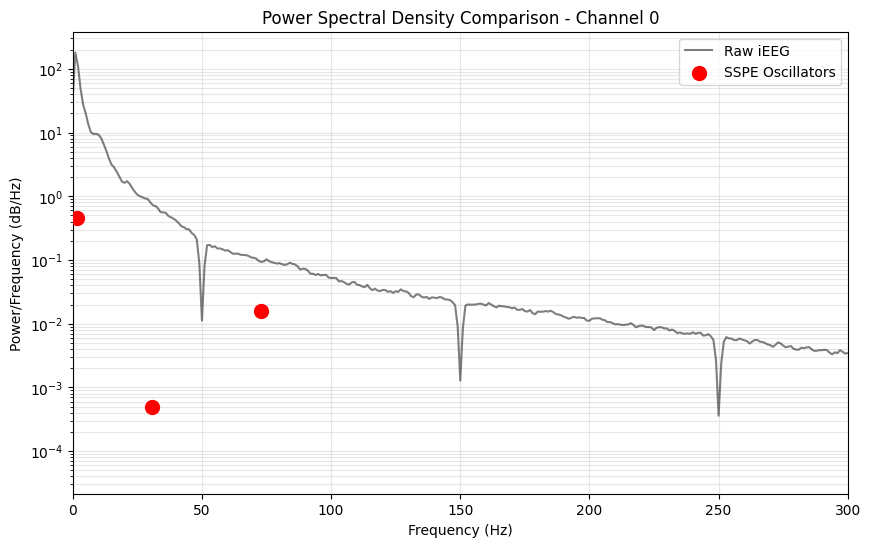

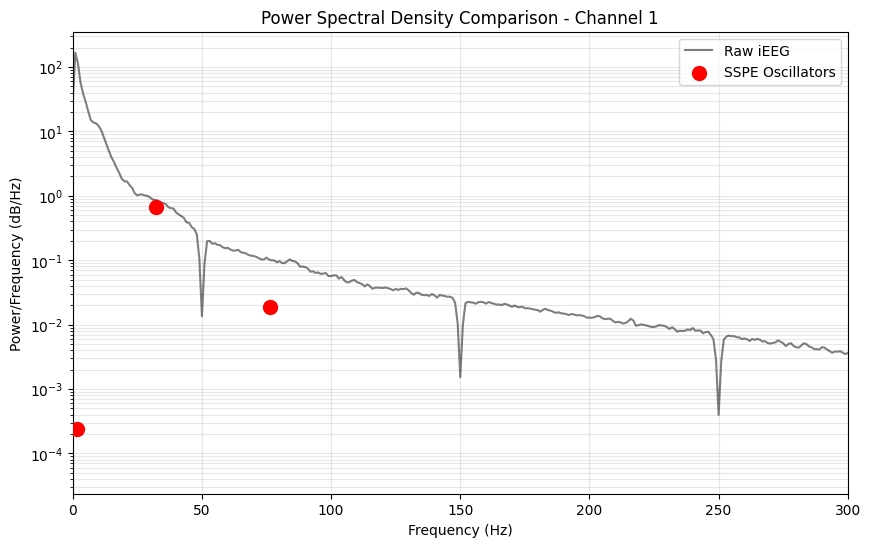

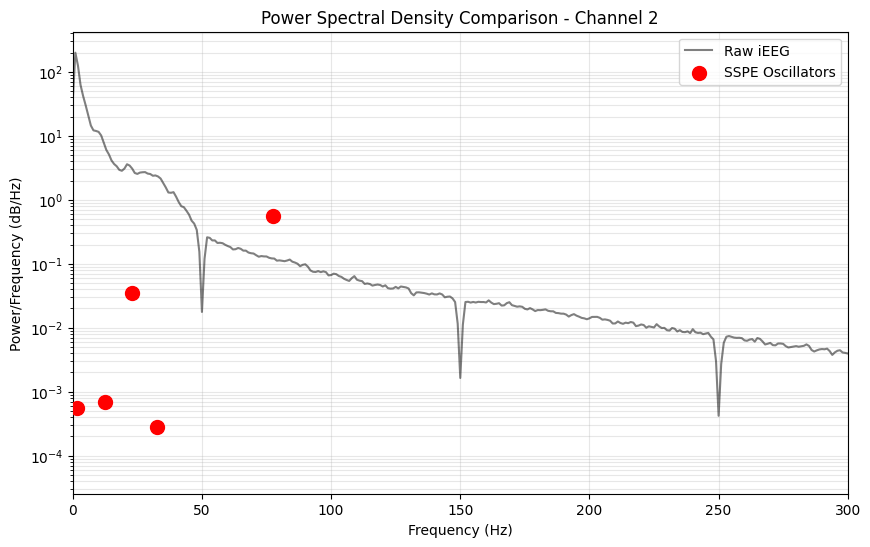

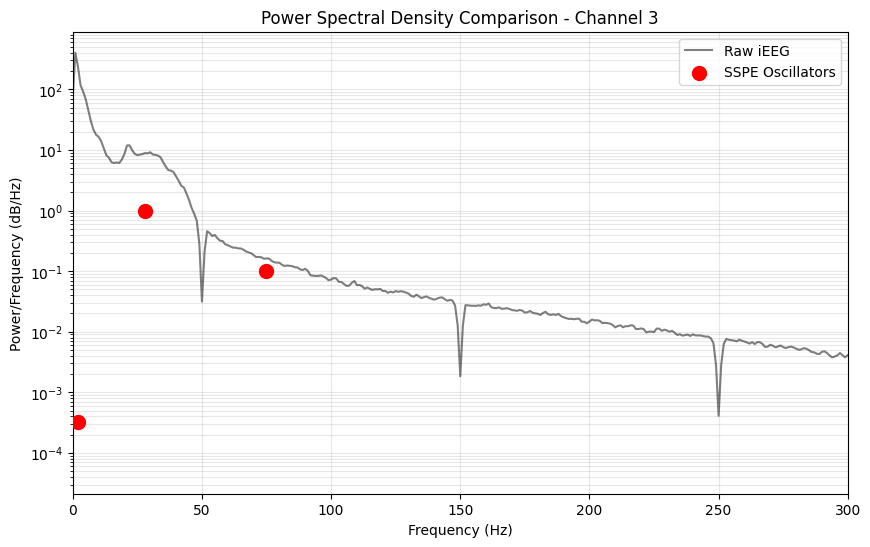

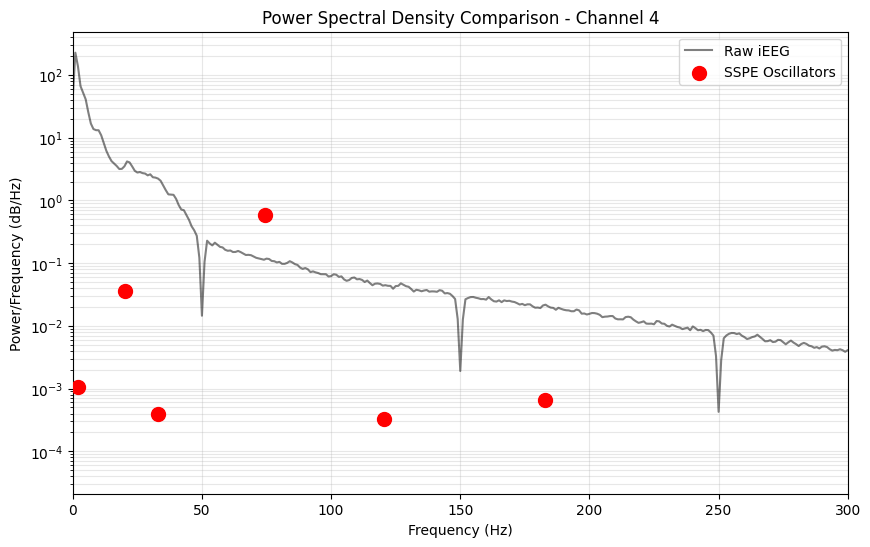

In [22]:
import scipy.signal
pt = 'sub-07'
data = get_eeg(pt, t_segment = 100)

#for the first channels
osc = [[ 1.57171376, 72.89608773, 30.67527927], [ 1.61172049, 32.21539268, 76.49096605],
       [ 1.46762755, 32.76762149, 77.56405255, 22.93725585, 12.44592291],
      [ 2.17824134, 27.86930719, 74.8655711 ],
    [1.92596477,  32.81044039,  74.30780164, 20.22396053, 182.98297061, 120.55085829]]

for ch_idx in range (0,5):
    plt.figure(figsize=(10, 6))
        
    # 1. Compute PSD for Raw Signal
    freqs_raw, psd_raw = welch(data[:, ch_idx], sr, nperseg=1024)
    plt.semilogy(freqs_raw, psd_raw, label='Raw iEEG', color='black', alpha=0.5)
    
    # 2. Compute PSD for SSPE Oscillators 
    sspe_stacked = np.load(os.path.join(feat_path,f'{pt}_SSPEfeat.npy'))
    nr_osc = len(osc[ch_idx])
    ch_freqs = osc[ch_idx]
    avg_amps = []
    for i in range(len(ch_freqs)):
        # Extract column for this oscillator
        col_data = sspe_stacked[:, idx + i]
        avg_amps.append(np.mean(col_data))
        #print (col_data)
        #print(np.mean(col_data))
            
    idx += nr_osc
    
    # SSPE: amplitude at each frequency
    # Note: Since PSD is Power (Amplitude^2), we square the mean amplitude for comparison
    plt.scatter(ch_freqs, np.array(avg_amps)**2/ sr, color='red', s=100, zorder=3, label='SSPE Oscillators')
    
    plt.title(f'Power Spectral Density Comparison - Channel {ch_idx}')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Power/Frequency (dB/Hz)')
    plt.xlim([0, 300]) # Focus on the High-Gamma range
    plt.legend()
    plt.grid(True, which='both', alpha=0.3)
    plt.show()

{'freqs': array([ 1.57171376, 72.89608773, 30.67527927]), 'Fs': 1024, 'ampVec': array([0.99555024, 0.9515532 , 0.98708154]), 'sigmaFreqs': array([3.97994972, 0.32491478, 0.21023946]), 'sigmaObs': 1, 'windowSize': 2000, 'lowFreqBand': None}

{'freqs': array([ 1.61172049, 32.21539268, 76.49096605]), 'Fs': 1024, 'ampVec': array([0.9966205 , 0.98246428, 0.96231847]), 'sigmaFreqs': array([4.6353358 , 0.4630824 , 0.18033479]), 'sigmaObs': 1, 'windowSize': 2000, 'lowFreqBand': None}

{'freqs': array([ 1.46762755, 32.76762149, 77.56405255, 22.93725585, 12.44592291]), 'Fs': 1024, 'ampVec': array([0.99758477, 0.98151142, 0.95492596, 0.99302318, 0.99340544]), 'sigmaFreqs': array([2.94761495, 1.34029573, 0.28380785, 0.25067668, 0.56827255]), 'sigmaObs': 1, 'windowSize': 2000, 'lowFreqBand': None}
77 hz power is above raw ieeg power, it has ampVec 0.95 and s 0.28

{'freqs': array([ 2.17824134, 27.86930719, 74.8655711 ]), 'Fs': 1024, 'ampVec': array([0.99810887, 0.99059548, 0.95936803]), 'sigmaFreqs': array([3.88624603, 3.76668931, 0.22734596]), 'sigmaObs': 1, 'windowSize': 2000, 'lowFreqBand': None}


{'freqs': array([  1.92596477,  32.81044039,  74.30780164,  20.22396053, 182.98297061, 120.55085829]), 'Fs': 1024,
'ampVec': array([0.99784674, 0.98744623, 0.96456095, 0.9929969 , 0.88396728, 0.90549209]), 
'sigmaFreqs': array([2.76033374, 0.79826621, 0.19099963, 0.52275793, 0.1354069 , 0.18351891]), 'sigmaObs': 1, 'windowSize': 2000, 'lowFreqBand': None}
74.3 Hz Osc has highest power, ampVec is 0.96 and sigmaFreqs is 0.19 which is is very "stiff" and the model is over-amplifying noise to fit. 
for the 182.9 Hz Osc ampVec is lower (0.88), on the plot we see that the red dot at 182Hz is much closer

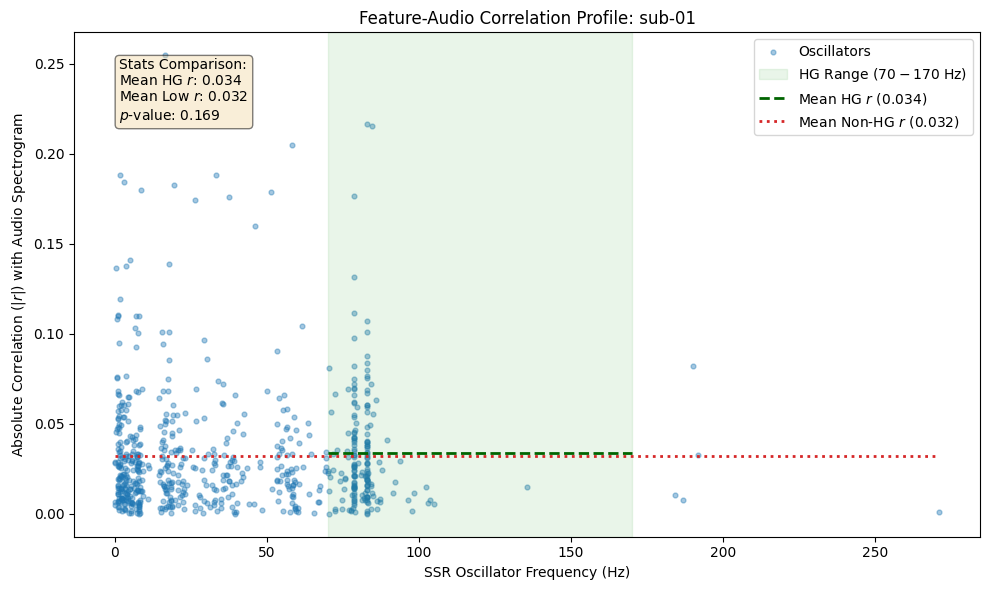

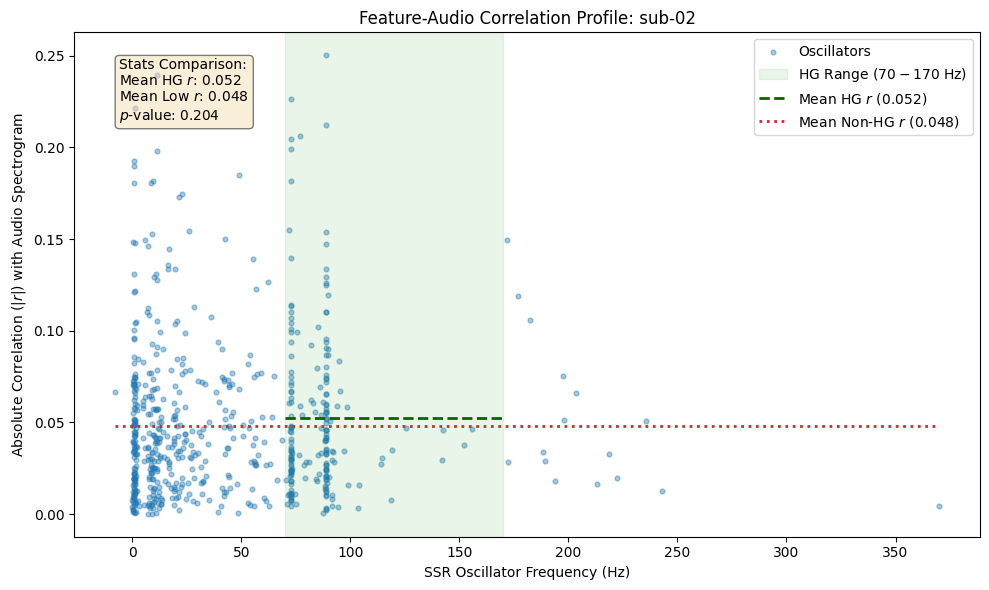

IndexError: index 534 is out of bounds for axis 1 with size 534

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# Helper function to calculate Cohen's d effect size
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return 0
    dof = nx + ny - 2
    pooled_std = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / dof)
    if pooled_std == 0:
        return 0
    return (np.mean(x) - np.mean(y)) / pooled_std

pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10']

for pt in pts:
    sspe = np.load(os.path.join(feat_path, f'{pt}_unstacked_SSPEfeat.npy'))
    initParams_list = get_initParams(pt)
    
    spectrogram = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
    audio_env = np.mean(spectrogram, axis=1)
    audio_env = (audio_env - np.mean(audio_env)) / np.std(audio_env)
    
    all_freqs = []
    all_corrs = []    
    
    # Loop through every channel
    start_col = 0
    for ch_idx in range(len(initParams_list)):
        freqs = initParams_list[ch_idx]['freqs']
        n_osc = len(freqs)
        
        # Calculate correlation for every oscillator in this channel
        for i in range(n_osc):
            osc_data = sspe[:len(audio_env), start_col + i]
            osc_data = (osc_data - np.mean(osc_data)) / np.std(osc_data)
            
            # --- FIX: Calculate the actual correlation coefficient ---
            r = np.corrcoef(osc_data, audio_env)[0, 1]
            
            all_freqs.append(freqs[i])
            all_corrs.append(abs(r)) # Use absolute r to see 'magnitude'
            
        start_col += n_osc
        
    all_freqs = np.array(all_freqs)
    all_corrs = np.array(all_corrs)
    
    # --- NUMERIC STATS CODE ---
    # Separate into HG and non-HG arrays
    hg_mask = (all_freqs >= 70) & (all_freqs <= 170)
    hg_corrs = all_corrs[hg_mask]
    non_hg_corrs = all_corrs[~hg_mask]
    
    # Calculate means
    mean_hg = np.mean(hg_corrs) if len(hg_corrs) > 0 else 0
    mean_non_hg = np.mean(non_hg_corrs) if len(non_hg_corrs) > 0 else 0
    
    # Run Mann-Whitney U statistical test and compute effect size
    if len(hg_corrs) > 0 and len(non_hg_corrs) > 0:
        stat, p_val = mannwhitneyu(hg_corrs, non_hg_corrs, alternative='greater')
        #effect_size = cohen_d(hg_corrs, non_hg_corrs)
    else:
        p_val, effect_size = 1.0, 0.0
    
    # Plot Correlation vs. Frequency
    plt.figure(figsize=(10, 6))
    plt.scatter(all_freqs, all_corrs, alpha=0.4, s=12, color='C0', label='Oscillators')
    plt.axvspan(70, 170, color='C2', alpha=0.1, label='HG Range ($70-170$ Hz)')
    
    # Plot group mean lines to visually assist the viewer
    if len(hg_corrs) > 0:
        plt.hlines(mean_hg, 70, 170, colors='darkgreen', linestyles='--', linewidth=2, label=f'Mean HG $r$ ({mean_hg:.3f})')
    plt.hlines(mean_non_hg, min(all_freqs), max(all_freqs), colors='C3', linestyles=':', linewidth=2, label=f'Mean Non-HG $r$ ({mean_non_hg:.3f})')
    
    # Create a nice floating statistics text box on the plot
    stats_text = (f"Stats Comparison:\n"
                  f"Mean HG $r$: {mean_hg:.3f}\n"
                  f"Mean Low $r$: {mean_non_hg:.3f}\n"
                  #f"Cohen's $d$: {effect_size:.2f}\n"
                  f"$p$-value: {p_val:.3f}")
    
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    plt.gca().text(0.05, 0.95, stats_text, transform=plt.gca().transAxes, fontsize=10,
            verticalalignment='top', bbox=props)
    
    plt.title(f'Feature-Audio Correlation Profile: {pt}')
    plt.xlabel('SSR Oscillator Frequency (Hz)')
    plt.ylabel('Absolute Correlation ($|r|$) with Audio Spectrogram')
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

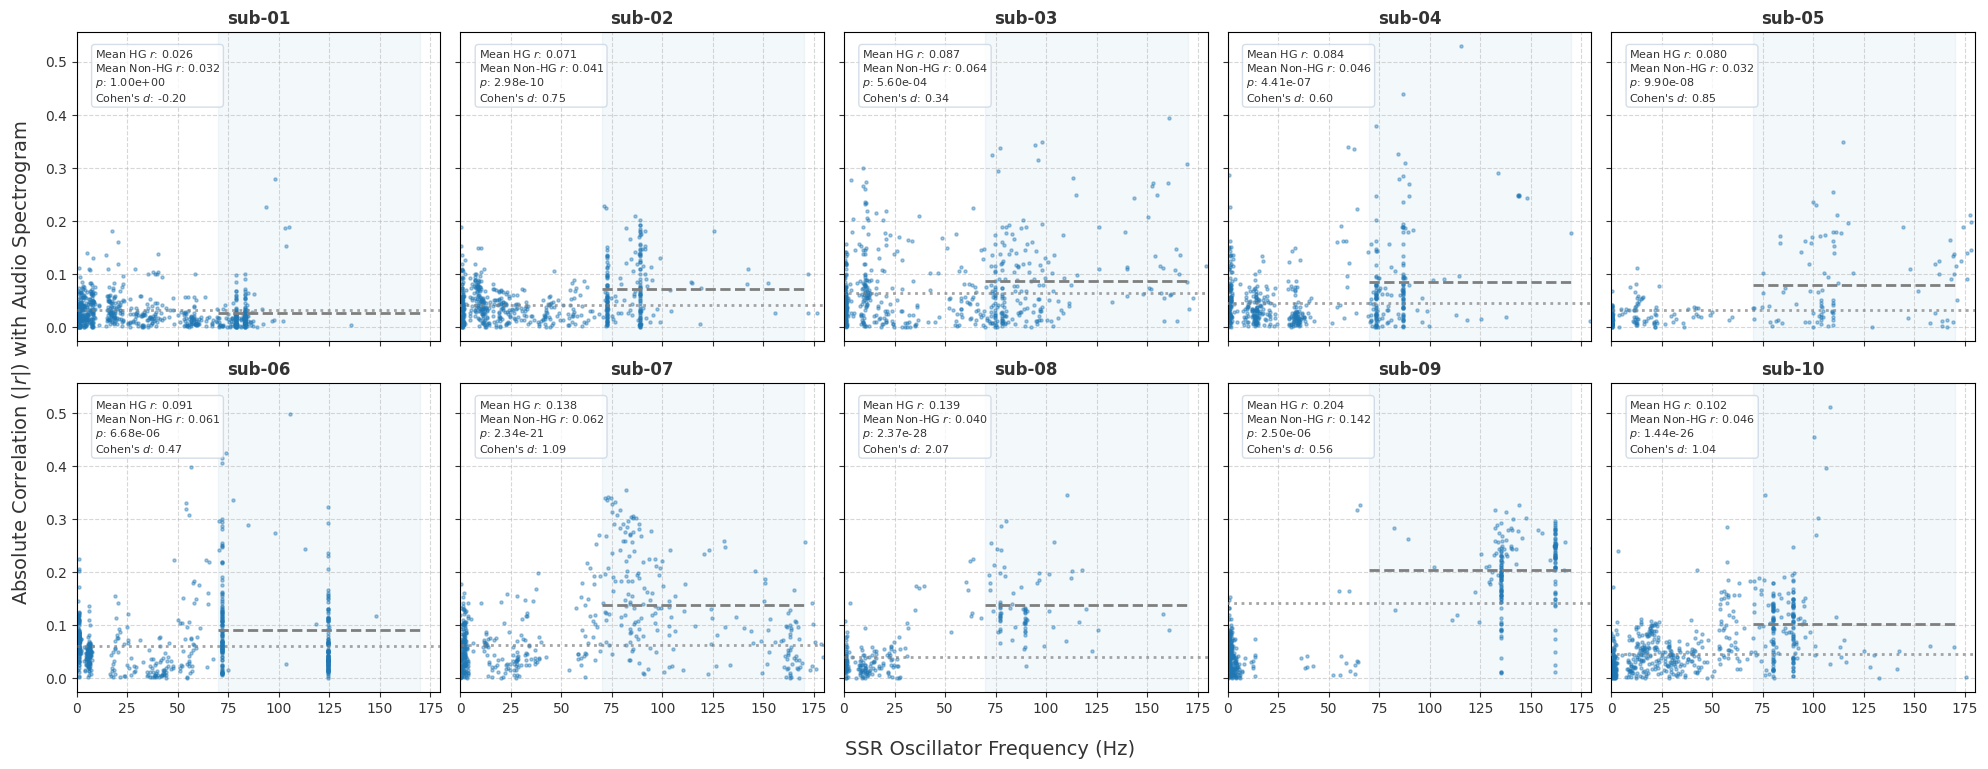

In [21]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# Helper function to calculate Cohen's d effect size
def cohen_d(x, y):
    nx, ny = len(x), len(y)
    if nx == 0 or ny == 0:
        return 0
    dof = nx + ny - 2
    pooled_std = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / dof)
    if pooled_std == 0:
        return 0
    return (np.mean(x) - np.mean(y)) / pooled_std

pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10']


fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

# 3. Main processing and plotting loop
for i, pt in enumerate(pts):
    ax = axes[i]
    
    # --- Load your data streams ---
    sspe = np.load(os.path.join(feat_path, f'{pt}_onlyAMP_SSPEfeat.npy'))
    initParams_list = get_initParams(pt)
    
    spectrogram = np.load(os.path.join(feat_path, f'{pt}_spec.npy'))
    audio_env = np.mean(spectrogram, axis=1)
    audio_env = (audio_env - np.mean(audio_env)) / np.std(audio_env)
    
    all_freqs = []
    all_corrs = []    
    
    # Loop through every channel
    start_col = 0
    for ch_idx in range(len(initParams_list)):
        freqs = initParams_list[ch_idx]['freqs']
        n_osc = len(freqs)
        
        # Calculate correlation for every oscillator in this channel
        for j in range(n_osc):
            osc_data = sspe[:len(audio_env), start_col + j]
            osc_data = (osc_data - np.mean(osc_data)) / np.std(osc_data)
            
            r = np.corrcoef(osc_data, audio_env)[0, 1]
            
            all_freqs.append(freqs[j])
            all_corrs.append(abs(r)) 
            
        start_col += n_osc
        
    all_freqs = np.array(all_freqs)
    all_corrs = np.array(all_corrs)
    
    # --- Numeric Stats ---
    hg_mask = (all_freqs >= 70) & (all_freqs <= 170)
    hg_corrs = all_corrs[hg_mask]
    non_hg_corrs = all_corrs[~hg_mask]
    
    mean_hg = np.mean(hg_corrs) if len(hg_corrs) > 0 else 0
    mean_non_hg = np.mean(non_hg_corrs) if len(non_hg_corrs) > 0 else 0

    d_val = cohen_d(hg_corrs, non_hg_corrs)
    
    if len(hg_corrs) > 0 and len(non_hg_corrs) > 0:
        stat, p_val = mannwhitneyu(hg_corrs, non_hg_corrs, alternative='greater')
    else:
        p_val = 1.0
    
    # --- Plotting onto the target grid cell axis ---
    # Draw background HG area shading using an unobtrusive neutral gray tint
    ax.axvspan(70, 170, color='C0', alpha=0.05, zorder=1)
    
    # Scatter points drawn using the participant's dedicated color
    ax.scatter(all_freqs, all_corrs, alpha=0.4, s=5, color='C0', zorder=2)
    
    # Draw group mean horizontal line indicators
    if len(hg_corrs) > 0:
        ax.hlines(mean_hg, 70, 170, colors='C7', linestyles='--', linewidth=2, zorder=3)
    ax.hlines(mean_non_hg, min(all_freqs), max(all_freqs), alpha=0.7, colors='C7', linestyles=':', linewidth=2, zorder=3)
    
    # Overlay the statistics values directly inside the subplot background cleanly
    stats_text = (f"Mean HG $r$: {mean_hg:.3f}\n"
                  f"Mean Non-HG $r$: {mean_non_hg:.3f}\n"
                  f"$p$: {p_val:.2e}\n"#p_val:.3f}")
                  f"Cohen's $d$: {d_val:.2f}")
    
    props = dict(boxstyle='round,pad=0.3', facecolor='#ffffff', edgecolor='#cbd5e1', alpha=0.8)
    ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=8,
            verticalalignment='top', bbox=props)
    
    # Format Subplot Borders and Labels
    ax.set_title(pt, fontsize=12)
    ax.set_xlim([0, 180])
    ax.grid(True, which='both', linestyle='--', alpha=0.5)

# 4. Global labels mapping across the master figure borders
fig.text(0.5, 0.01, 'SSR Oscillator Frequency (Hz)', ha='center', fontsize=14)
fig.text(0.01, 0.5, 'Absolute Correlation ($|r|$) with Audio Spectrogram', va='center', rotation='vertical', fontsize=14)

plt.tight_layout(rect=[0.02, 0.04, 1, 0.96])

# Save and render final master grid
plt.savefig(os.path.join(result_path, 'Feature_Audio_Correlations_All_Subjects.png'), dpi=300)
plt.show()

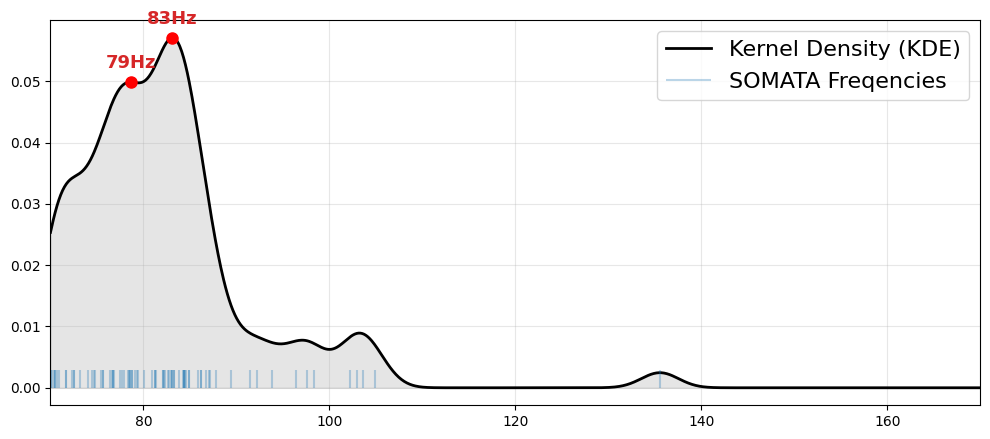

no hg in 50 channels


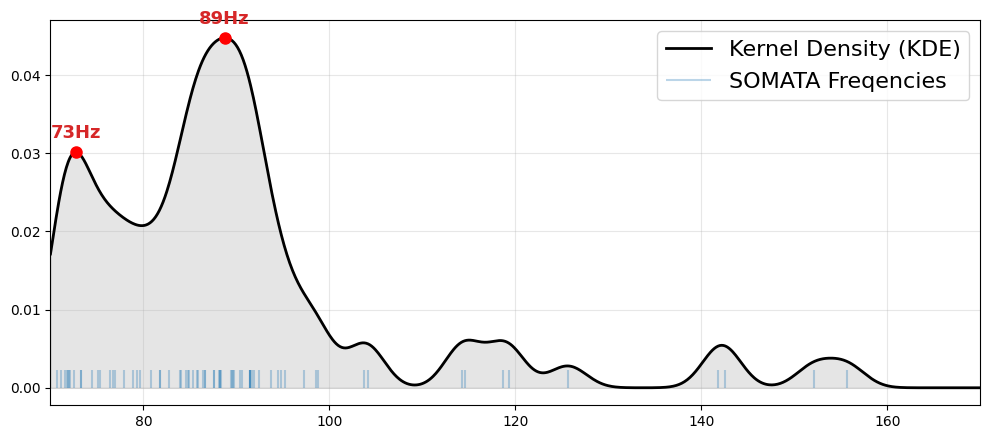

no hg in 62 channels


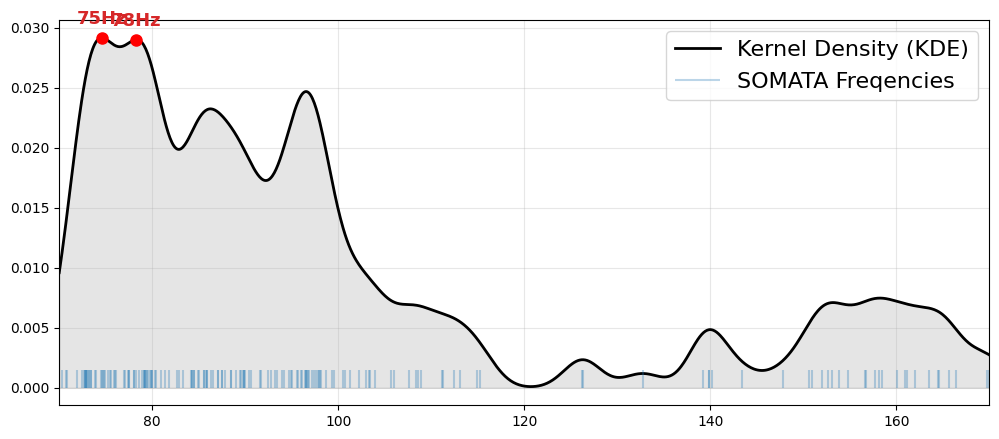

no hg in 17 channels


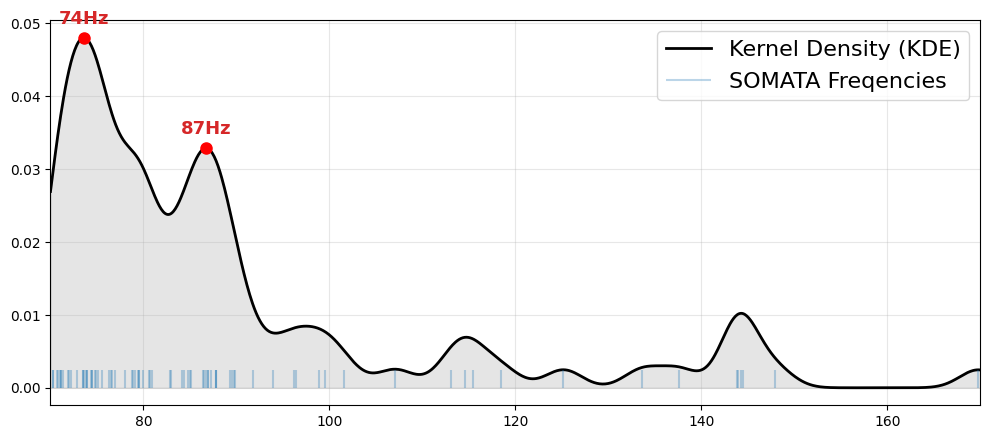

no hg in 45 channels


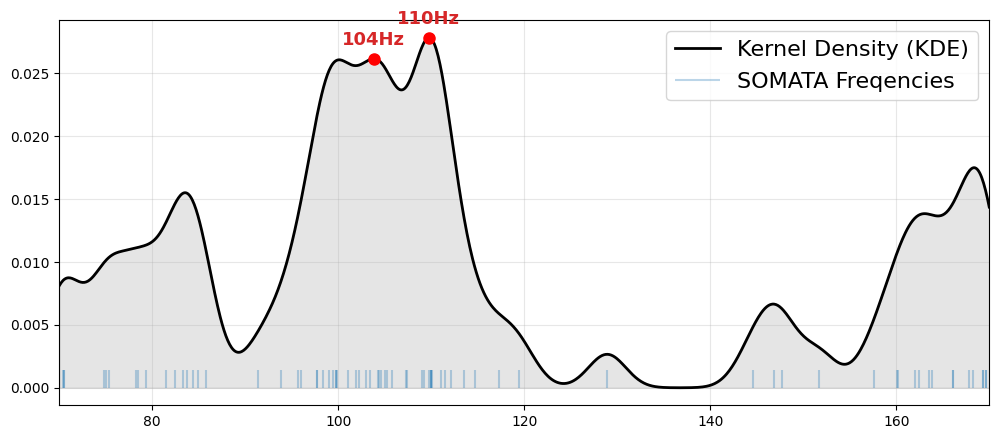

no hg in 7 channels


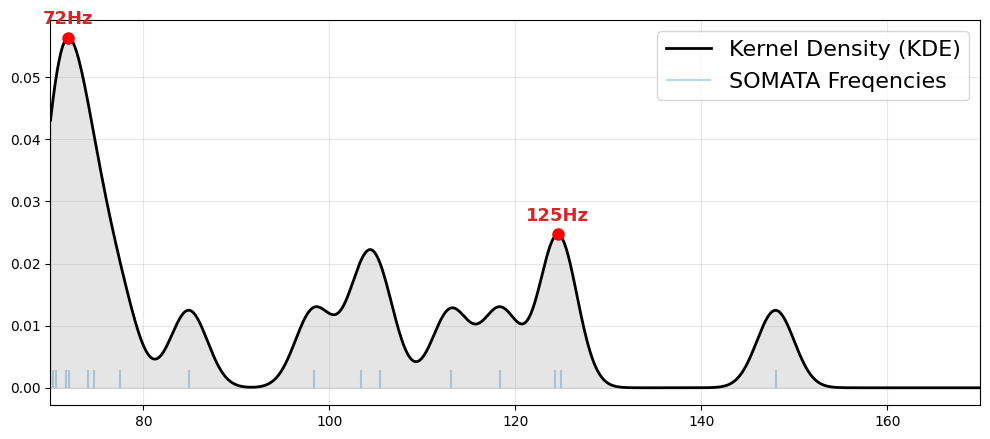

no hg in 114 channels


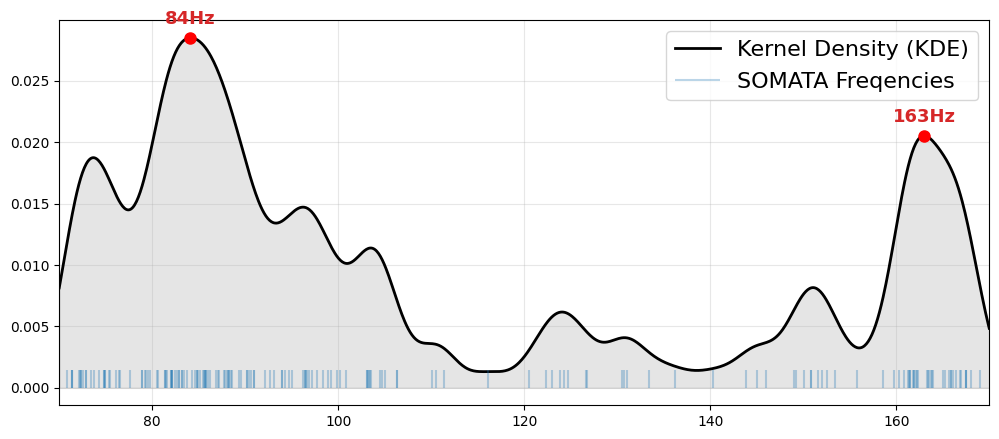

no hg in 7 channels


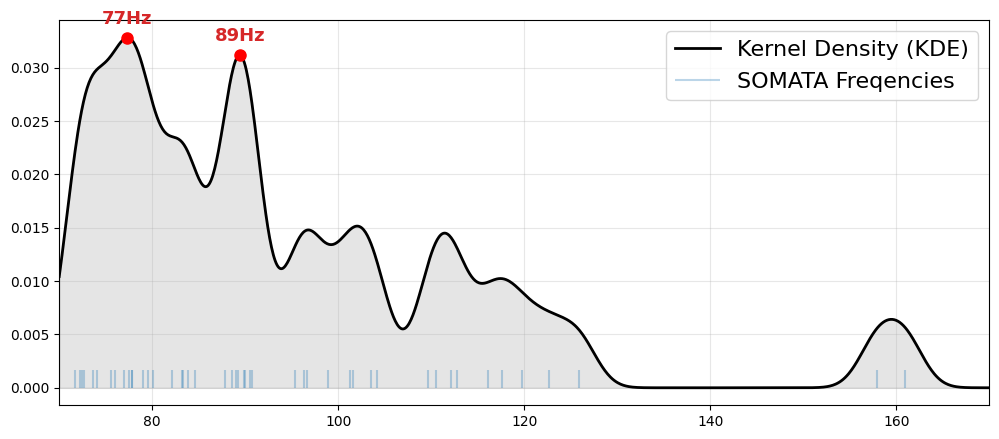

no hg in 15 channels


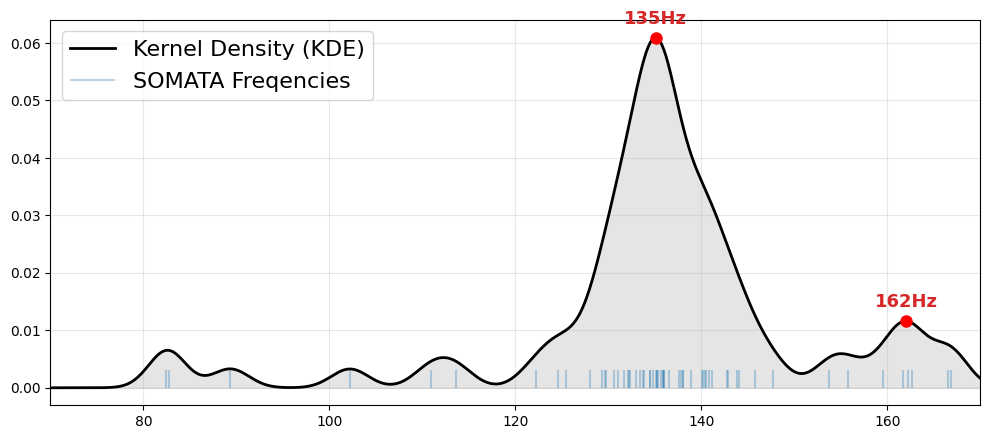

no hg in 60 channels


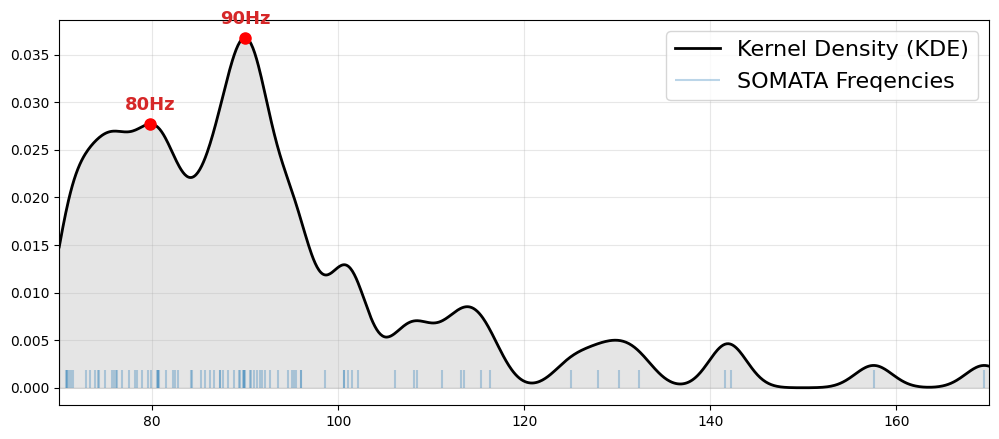

no hg in 51 channels


In [2]:
pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05','sub-06','sub-07', 'sub-08', 'sub-09', 'sub-10']

for pt in pts:
    get_initParams(pt)

In [2]:
run_extract_features('sub-01', SSPE=False)

extracted features


In [2]:

pts = ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05','sub-06','sub-07', 'sub-08', 'sub-09', 'sub-10']



for pt in pts:
    run_extract_features(pt, SSPE=False, low_pass = True, saveAs='_hp_lp_bandpassfeat')

extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features


In [3]:
for pt in pts:
    run_extract_features(pt, SSPE=False, low_pass = False, saveAs='_hp_bandpassfeat')

extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features
extracted features


In [4]:
reconstruct(pts=None,  n_comp = 5, feat_suffix='_hp_lp_bandpassfeat.npy', unstacked =False, saveAs='_hp_lp_bandpass')
reconstruct(pts=None,  n_comp = 5, feat_suffix='_hp_bandpassfeat.npy', unstacked =False, saveAs='_hp_bandpass')

sub-01 has mean correlation of 0.592664
save pac
sub-02 has mean correlation of 0.660817
save pac
sub-03 has mean correlation of 0.837761
save pac
sub-04 has mean correlation of 0.811054
save pac
sub-05 has mean correlation of 0.547425
save pac
sub-06 has mean correlation of 0.865710
save pac
sub-07 has mean correlation of 0.716559
save pac
sub-08 has mean correlation of 0.731899
save pac
sub-09 has mean correlation of 0.656616
save pac
sub-10 has mean correlation of 0.688712
save pac
sub-01 has mean correlation of 0.587810
save pac
sub-02 has mean correlation of 0.661491
save pac
sub-03 has mean correlation of 0.847947
save pac
sub-04 has mean correlation of 0.802016
save pac
sub-05 has mean correlation of 0.586065
save pac
sub-06 has mean correlation of 0.872799
save pac
sub-07 has mean correlation of 0.716075
save pac
sub-08 has mean correlation of 0.738045
save pac
sub-09 has mean correlation of 0.676643
save pac
sub-10 has mean correlation of 0.698977
save pac


(array([[[0.38042427, 0.46279272, 0.58723283, ..., 0.52141853,
          0.51373493, 0.47868625],
         [0.54818257, 0.58457468, 0.59348726, ..., 0.45104975,
          0.41905836, 0.36389238],
         [0.53875835, 0.55756496, 0.61250292, ..., 0.37657377,
          0.33668849, 0.28423546],
         ...,
         [0.50193504, 0.54336036, 0.58461193, ..., 0.49708757,
          0.47798501, 0.44427083],
         [0.61515738, 0.64863396, 0.68244433, ..., 0.54636309,
          0.52497695, 0.46361057],
         [0.64966173, 0.67431787, 0.69740411, ..., 0.50143778,
          0.48396915, 0.4213952 ]],
 
        [[0.71708852, 0.72474557, 0.73072336, ..., 0.69735985,
          0.6701873 , 0.58918247],
         [0.64944364, 0.67537063, 0.67571378, ..., 0.60366426,
          0.58296294, 0.51810352],
         [0.67108292, 0.68855326, 0.69419428, ..., 0.63415332,
          0.60899404, 0.51974492],
         ...,
         [0.66242122, 0.66489945, 0.68905956, ..., 0.67666339,
          0.63897765, 0.